# Data Analytics in Supply Chain Management — Project Part 1
## Dataset 1: Manufacturing Energy Consumption (Regression)

**Course:** Data Analytics in Supply Chain Management — Fall 2026  
**Project:** Project Part 1  
**Use Case:** Manufacturing Energy Consumption (Regression)  
**Dataset file:** `regression_manufacturing.csv`

### Purpose

This notebook performs the **Exploratory Data Analysis (EDA)** and **brainstorming** required for Dataset 1. It follows the project brief and grading criteria: dataset dimensions and statistical features, data types and missing values, categorical analysis, numerical-variable analysis, outlier detection, relationships among variables, bonus visualizations, and evidence-supported brainstorming.

> **Scope discipline:** Project Part 1 asks us to explore the dataset and later build regression models. This notebook therefore focuses on EDA and hypothesis generation rather than training a final regression model.

### Scenario

The smart-factory scenario asks an analytics team to understand how production, machine condition, maintenance, human, and environmental factors are associated with unusually high energy use, while preparing the data for later prediction of `Energy_Consumption_kWh`.

### Analytical task

The dataset is described in the project brief as a machine-day regression problem with `Energy_Consumption_kWh` as the dependent variable. The brief explicitly notes that the underlying data may contain **nonlinear patterns**, including overload and overheating thresholds, U-shaped operating regions, diminishing returns, and interactions between machine condition and production requirements.

**Primary target:** `Energy_Consumption_kWh`

**Important:** The raw CSV is loaded without modifying its values. Any date parsing or temporary variables used for EDA are created on copies.


## Figure 1 — Project use case

The uploaded project image frames the problem around five groups of factors: **machine settings**, **production volume**, **environmental conditions**, **equipment condition and maintenance**, and the resulting **energy consumption (kWh)**.

The image is reproduced below for direct connection between the project scenario and the variables examined in this notebook.


![Figure 1 — Manufacturing Energy Consumption use case](Figure_1_Manufacturing_Energy_Consumption_Use_Case.png)

*Figure 1. Use Case 1: Manufacturing Energy Consumption (uploaded project image).*

## 1. Reproducibility and imports

The analysis uses standard Python data-analysis and visualization libraries. A fixed random seed is used for sampling-based visualizations so that the notebook is reproducible.


In [61]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pandas.plotting import parallel_coordinates

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

DATA_PATH = Path("regression_manufacturing.csv")
if not DATA_PATH.exists():
    # Fallback for the uploaded ChatGPT working environment.
    DATA_PATH = Path("../MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/data/regression_manufacturing.csv")

assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"
print(f"Dataset path: {DATA_PATH.resolve()}")


Dataset path: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/data/regression_manufacturing.csv


In [32]:
from pathlib import Path

PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

def save_and_show(filename):
    """Save the current matplotlib figure as a high-resolution PNG, then display it."""
    output_path = PLOTS_DIR / filename
    plt.savefig(output_path, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Saved plot: {output_path.resolve()}")
    plt.show()

## 2. Load the raw dataset

The project brief describes **10,000 machine-day observations**, but the supplied CSV should be checked rather than assumed. We therefore report the actual dimensions of the uploaded file and explicitly flag any discrepancy.

No rows or values are removed at this stage.


In [33]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (10250, 20)


,Observation_ID,Production_Date,Machine_ID,Machine_Type,Shift,Machine_Age_years,Operating_Hours_per_Day,Production_Volume_units,Product_Complexity_Index,Material_Hardness_HB,Cycle_Time_sec,Spindle_Load_pct,Average_Machine_Temperature_C,Vibration_mm_s,Tool_Wear_Index,Days_Since_Maintenance,Operator_Experience_years,Ambient_Temperature_C,Humidity_pct,Energy_Consumption_kWh
0,1,2025-06-23,M042,Laser_Cutter,Day,3.130,17.990,683,7.850,199.000,84.240,87.960,78.170,2.098,0.408,22.800,6.020,19.470,59.060,"1,420.420"
1,2,2025-04-14,M012,Laser_Cutter,Day,5.280,14.720,584,5.330,236.900,69.630,65.000,74.680,2.473,0.685,81.600,5.120,21.310,41.700,337.380
2,3,2025-06-21,M004,CNC_Grinder,Day,9.050,20.860,580,2.340,272.000,98.710,57.190,78.100,3.026,0.459,31.100,16.190,26.210,45.390,291.230
3,4,2025-12-19,M006,Laser_Cutter,Day,14.140,15.460,570,6.550,293.600,70.350,81.310,78.050,3.963,0.464,31.000,16.590,7.670,74.090,381.940
4,5,2025-01-29,M049,CNC_Lathe,Evening,2.670,17.910,651,5.140,221.400,62.870,58.250,79.530,1.461,0.330,14.400,6.720,12.460,76.650,242.100


### 2.1 Dataset integrity checks

The project brief states that `Observation_ID` is a unique row identifier and should not be used as a predictive feature. We check uniqueness, duplicate rows, date coverage, and unexpected categorical levels.

These checks are **diagnostic only**. The raw dataset remains unchanged.


In [34]:
TARGET = "Energy_Consumption_kWh"
ID_COL = "Observation_ID"
DATE_COL = "Production_Date"

# Parse date only in the analysis copy.
df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")

print("Rows:", len(df))
print("Columns:", df.shape[1])
print("Unique Observation_ID:", df[ID_COL].nunique())
print("Duplicated Observation_ID rows:", df[ID_COL].duplicated().sum())
print("Exact duplicate rows:", df.duplicated().sum())
print("Date range:", df[DATE_COL].min().date(), "to", df[DATE_COL].max().date())

expected_machine_types = {"CNC_Mill", "CNC_Lathe", "CNC_Grinder", "Laser_Cutter"}
expected_shifts = {"Day", "Evening", "Night"}

print("\nUnexpected Machine_Type values:", sorted(set(df["Machine_Type"].dropna()) - expected_machine_types))
print("Unexpected Shift values:", sorted(set(df["Shift"].dropna()) - expected_shifts))


Rows: 10250
Columns: 20
Unique Observation_ID: 10000
Duplicated Observation_ID rows: 250
Exact duplicate rows: 228
Date range: 2025-01-01 to 2025-12-31

Unexpected Machine_Type values: ['Tree']
Unexpected Shift values: ['Dream']


### Initial data-quality interpretation

The supplied file contains **10,250 rows and 20 columns**, rather than exactly 10,000 rows. `Observation_ID` spans 1–10,000 but is not unique across all rows, so duplicate identifiers are present. The file also contains a small number of categorical values outside the four machine types and three shifts specified in the project description.

These are important findings for the EDA because they affect how the dataset should be interpreted. **They are not silently corrected in this Part 1 notebook.** In particular, `Observation_ID` is treated as an identifier and excluded from substantive relationship analysis.


# 3. Exploratory Data Analysis

## 3.1 Dimension of the dataset and basic statistical features

This section directly addresses the grading criterion for dataset dimensions and statistical characteristics.


In [35]:
print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()

print("\nNumeric columns:", len(numeric_cols))
print("Categorical/text columns:", len(categorical_cols))

display(df[numeric_cols].describe().T)


Shape: (10250, 20)
Rows: 10250
Columns: 20

Numeric columns: 16
Categorical/text columns: 3


,count,mean,std,min,25%,50%,75%,max
Observation_ID,"10,250.000","4,997.199","2,887.196",1.000,"2,502.250","4,997.500","7,501.750","10,000.000"
Machine_Age_years,"10,250.000",8.159,3.926,1.470,4.850,7.900,12.360,14.740
Operating_Hours_per_Day,"10,250.000",15.950,3.573,6.000,13.530,15.990,18.468,24.000
Production_Volume_units,"10,250.000",532.788,182.838,127.000,404.000,507.000,629.000,"1,800.000"
Product_Complexity_Index,"10,250.000",5.392,1.956,1.040,3.860,5.360,6.910,9.960
Material_Hardness_HB,"10,250.000",253.153,33.523,131.800,230.100,252.700,275.800,360.000
Cycle_Time_sec,"10,250.000",89.945,28.497,26.630,75.272,87.765,100.790,384.940
Spindle_Load_pct,"10,250.000",65.760,11.602,28.900,57.502,65.690,73.978,98.000
Average_Machine_Temperature_C,"9,839.000",75.381,14.831,54.340,70.460,74.090,77.695,255.650
Vibration_mm_s,"9,738.000",2.473,0.864,0.648,1.995,2.415,2.823,11.050


### 3.2 Feature inventory aligned with the project scenario

The project brief groups the predictors conceptually into production, machine-condition, maintenance, human, and environmental factors. The table below preserves the supplied feature names while assigning an analytical role for EDA.

| Project role | Variables examined |
|---|---|
| Identifier / calendar | `Observation_ID`, `Production_Date`, `Machine_ID` |
| Machine configuration | `Machine_Type`, `Shift` |
| Production | `Operating_Hours_per_Day`, `Production_Volume_units`, `Product_Complexity_Index`, `Material_Hardness_HB`, `Cycle_Time_sec`, `Spindle_Load_pct` |
| Machine condition | `Average_Machine_Temperature_C`, `Vibration_mm_s`, `Tool_Wear_Index` |
| Maintenance | `Days_Since_Maintenance` |
| Human factor | `Operator_Experience_years` |
| Environment | `Ambient_Temperature_C`, `Humidity_pct` |
| Target | `Energy_Consumption_kWh` |

The use-case image (Figure 1) motivates this grouping: machine settings, production volume, equipment condition/maintenance, environmental conditions, and energy consumption are explicitly highlighted.


## 4. Data types and missing-value detection

Missing values are not imputed in this EDA. Imputation would be a modeling/data-preparation decision and could change distributions. Instead, missingness is quantified and its possible analytical implications are recorded.

For predictive work, missing-value handling should be performed inside a reproducible preprocessing workflow rather than by silently replacing values during EDA.


In [36]:
dtype_table = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": df.isna().mean().mul(100).round(2),
    "unique_values": df.nunique(dropna=True)
}).sort_values(["missing_pct", "data_type"], ascending=[False, True])

display(dtype_table)


,data_type,non_null,missing,missing_pct,unique_values
Tool_Wear_Index,float64,9633,617,6.020,860
Vibration_mm_s,float64,9738,512,5.000,2518
Average_Machine_Temperature_C,float64,9839,411,4.010,2441
Energy_Consumption_kWh,float64,9839,411,4.010,7921
Humidity_pct,float64,9940,310,3.020,3735
Production_Date,datetime64[ns],10250,0,0.000,365
Machine_Age_years,float64,10250,0,0.000,1299
Operating_Hours_per_Day,float64,10250,0,0.000,1598
Product_Complexity_Index,float64,10250,0,0.000,863
Material_Hardness_HB,float64,10250,0,0.000,1596


,missing_count,missing_pct
Tool_Wear_Index,617,6.020
Vibration_mm_s,512,5.000
Energy_Consumption_kWh,411,4.010
Average_Machine_Temperature_C,411,4.010
Humidity_pct,310,3.020


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots/Figure_02_Missing_Value_Rate_by_Feature.png


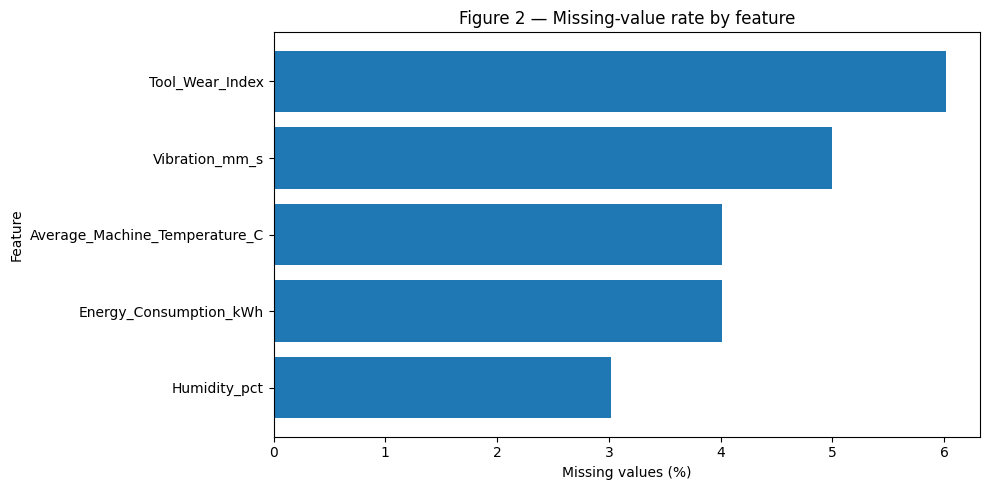

In [37]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

missing_table = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": missing_pct
})
display(missing_table[missing_table["missing_count"] > 0])

plt.figure(figsize=(10, 5))
m = missing_table[missing_table["missing_count"] > 0].sort_values("missing_count")
plt.barh(m.index, m["missing_pct"])
plt.xlabel("Missing values (%)")
plt.ylabel("Feature")
plt.title("Figure 2 — Missing-value rate by feature")
plt.tight_layout()
save_and_show("Figure_02_Missing_Value_Rate_by_Feature.png")


**Figure 2 interpretation.** Missingness is concentrated in `Tool_Wear_Index`, `Vibration_mm_s`, `Average_Machine_Temperature_C`, `Energy_Consumption_kWh`, and `Humidity_pct`. The target itself contains missing values, so rows with an unknown target cannot be used for supervised regression training without a dedicated treatment. For EDA, target-related plots use only rows where the target is observed.

The missingness pattern is a data-quality finding, not evidence that missing observations should be replaced with a particular statistic.


# 5. Analysis of categorical variables

The project rubric explicitly requests categorical analysis using plots such as bar charts and pie charts. We analyze the operational categories while avoiding an unreadable 50-category pie chart for `Machine_ID`.


In [38]:
cat_summary = {}
for col in ["Machine_Type", "Shift", "Machine_ID"]:
    vc = df[col].value_counts(dropna=False)
    cat_summary[col] = pd.DataFrame({
        "count": vc,
        "percentage": (vc / len(df) * 100).round(2)
    })
    print(f"\n{col}")
    display(cat_summary[col].head(20))



Machine_Type


,count,percentage
Machine_Type,,
CNC_Mill,3700,36.100
CNC_Grinder,2282,22.260
CNC_Lathe,2261,22.060
Laser_Cutter,2002,19.530
Tree,5,0.050



Shift


,count,percentage
Shift,,
Day,5181,50.550
Evening,2947,28.750
Night,2117,20.650
Dream,5,0.050



Machine_ID


,count,percentage
Machine_ID,,
M026,240,2.340
M009,231,2.250
M014,225,2.200
M008,225,2.200
M043,224,2.190
M038,222,2.170
M040,222,2.170
M029,221,2.160
M025,217,2.120


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots/Figure_03_04_Machine_Type_and_Shift_Distribution.png


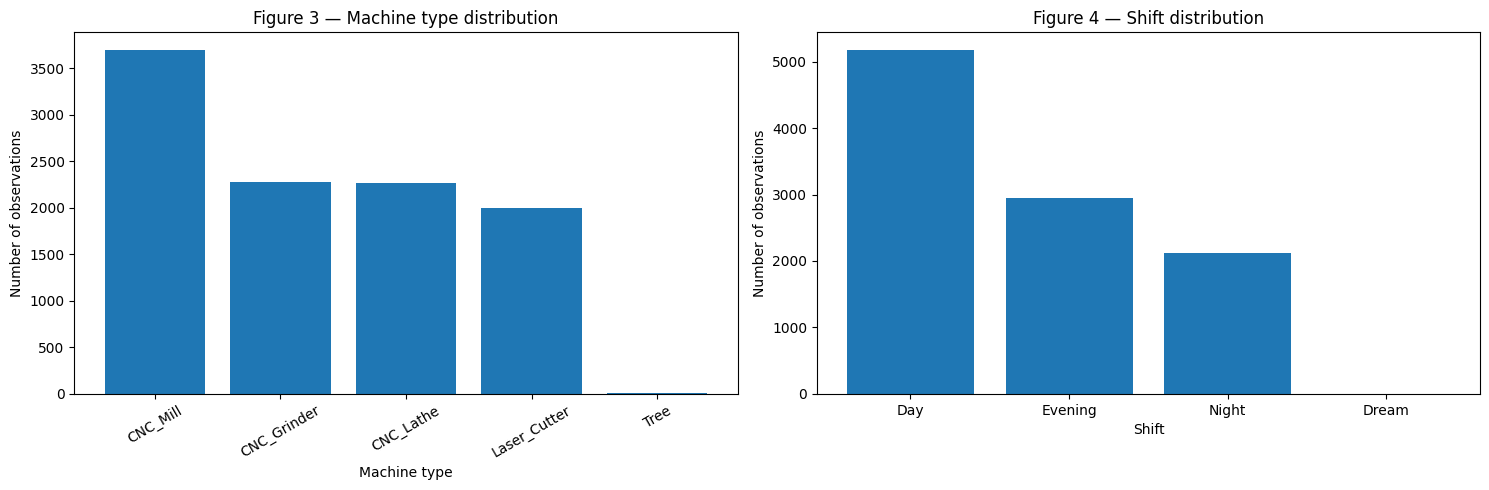

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

machine_type_counts = df["Machine_Type"].value_counts()
axes[0].bar(machine_type_counts.index, machine_type_counts.values)
axes[0].set_title("Figure 3 — Machine type distribution")
axes[0].set_xlabel("Machine type")
axes[0].set_ylabel("Number of observations")
axes[0].tick_params(axis="x", rotation=30)

shift_counts = df["Shift"].value_counts()
axes[1].bar(shift_counts.index, shift_counts.values)
axes[1].set_title("Figure 4 — Shift distribution")
axes[1].set_xlabel("Shift")
axes[1].set_ylabel("Number of observations")

plt.tight_layout()
save_and_show("Figure_03_04_Machine_Type_and_Shift_Distribution.png")


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots/Figure_05_06_Machine_Type_and_Shift_Share.png


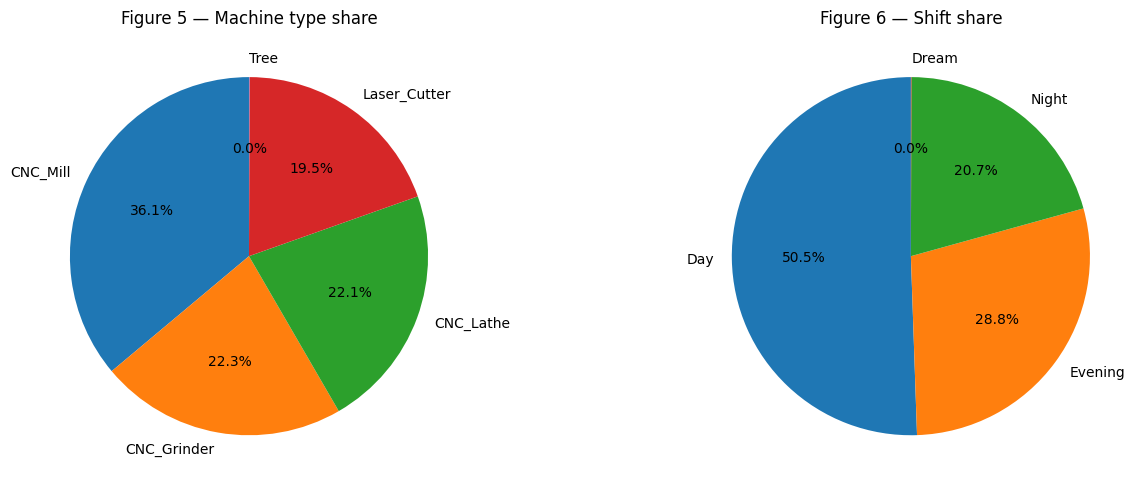

Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots/Figure_07_Top_15_Machine_ID_Frequencies.png


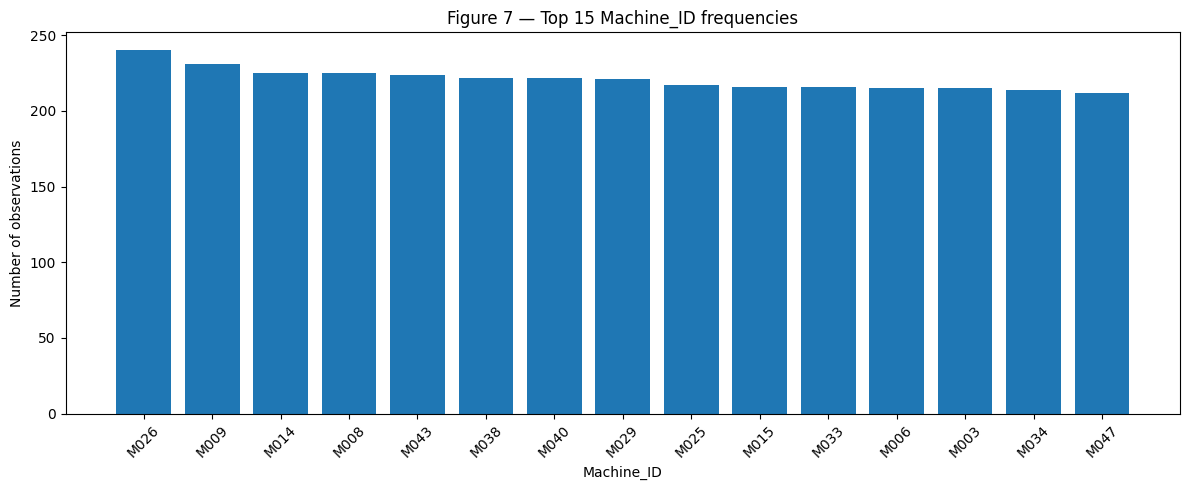

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].pie(
    machine_type_counts.values,
    labels=machine_type_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[0].set_title("Figure 5 — Machine type share")

axes[1].pie(
    shift_counts.values,
    labels=shift_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Figure 6 — Shift share")

plt.tight_layout()
save_and_show("Figure_05_06_Machine_Type_and_Shift_Share.png")

# Top 15 machine IDs for a readable categorical diagnostic.
top_machine_ids = df["Machine_ID"].value_counts().head(15)
plt.figure(figsize=(12, 5))
plt.bar(top_machine_ids.index, top_machine_ids.values)
plt.title("Figure 7 — Top 15 Machine_ID frequencies")
plt.xlabel("Machine_ID")
plt.ylabel("Number of observations")
plt.xticks(rotation=45)
plt.tight_layout()
save_and_show("Figure_07_Top_15_Machine_ID_Frequencies.png")


### Categorical findings

- `Machine_ID` contains many levels, so a full pie chart would be inappropriate; a frequency table and top-15 bar chart provide a more readable diagnostic.
- The supplied project description expects four machine types and three shifts. The raw file contains five observations with `Machine_Type = "Tree"` and five with `Shift = "Dream"`. These are retained for transparency and should be investigated before final modeling.
- The distribution of observations across machine types and shifts should be considered when comparing group-level energy consumption because the groups are not equally sized.


# 6. Analysis of numerical variables

The rubric requests box plots, violin plots, histograms, and distribution/KDE plots. Because the dataset contains many numeric variables, the notebook uses a complete numeric overview plus focused target-oriented visualizations.

`Observation_ID` is excluded from substantive numerical analysis because the project brief defines it as an identifier.


In [41]:
analysis_numeric_cols = [c for c in numeric_cols if c != ID_COL]

# Descriptive statistics with skewness for numerical EDA.
numeric_profile = df[analysis_numeric_cols].describe().T
numeric_profile["missing"] = df[analysis_numeric_cols].isna().sum()
numeric_profile["missing_pct"] = df[analysis_numeric_cols].isna().mean().mul(100)
numeric_profile["skewness"] = df[analysis_numeric_cols].skew(numeric_only=True)
display(numeric_profile.sort_index())


,count,mean,std,min,25%,50%,75%,max,missing,missing_pct,skewness
Ambient_Temperature_C,"10,250.000",18.052,7.638,5.000,11.300,17.990,24.688,37.110,0,0.000,0.039
Average_Machine_Temperature_C,"9,839.000",75.381,14.831,54.340,70.460,74.090,77.695,255.650,411,4.010,8.491
Cycle_Time_sec,"10,250.000",89.945,28.497,26.630,75.272,87.765,100.790,384.940,0,0.000,4.872
Days_Since_Maintenance,"10,250.000",33.379,20.766,0.500,18.000,29.100,44.500,100.000,0,0.000,1.020
Energy_Consumption_kWh,"9,839.000",317.052,112.766,134.940,260.695,302.260,350.510,"1,472.820",411,4.010,5.421
Humidity_pct,"9,940.000",59.864,10.138,25.000,52.860,59.790,66.933,90.000,310,3.024,-0.003
Machine_Age_years,"10,250.000",8.159,3.926,1.470,4.850,7.900,12.360,14.740,0,0.000,0.070
Material_Hardness_HB,"10,250.000",253.153,33.523,131.800,230.100,252.700,275.800,360.000,0,0.000,0.041
Operating_Hours_per_Day,"10,250.000",15.950,3.573,6.000,13.530,15.990,18.468,24.000,0,0.000,-0.081
Operator_Experience_years,"10,250.000",6.216,4.216,0.200,3.060,5.250,8.340,22.000,0,0.000,1.164


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots/Figure_08_Numerical_Variable_Distributions_with_KDE.png


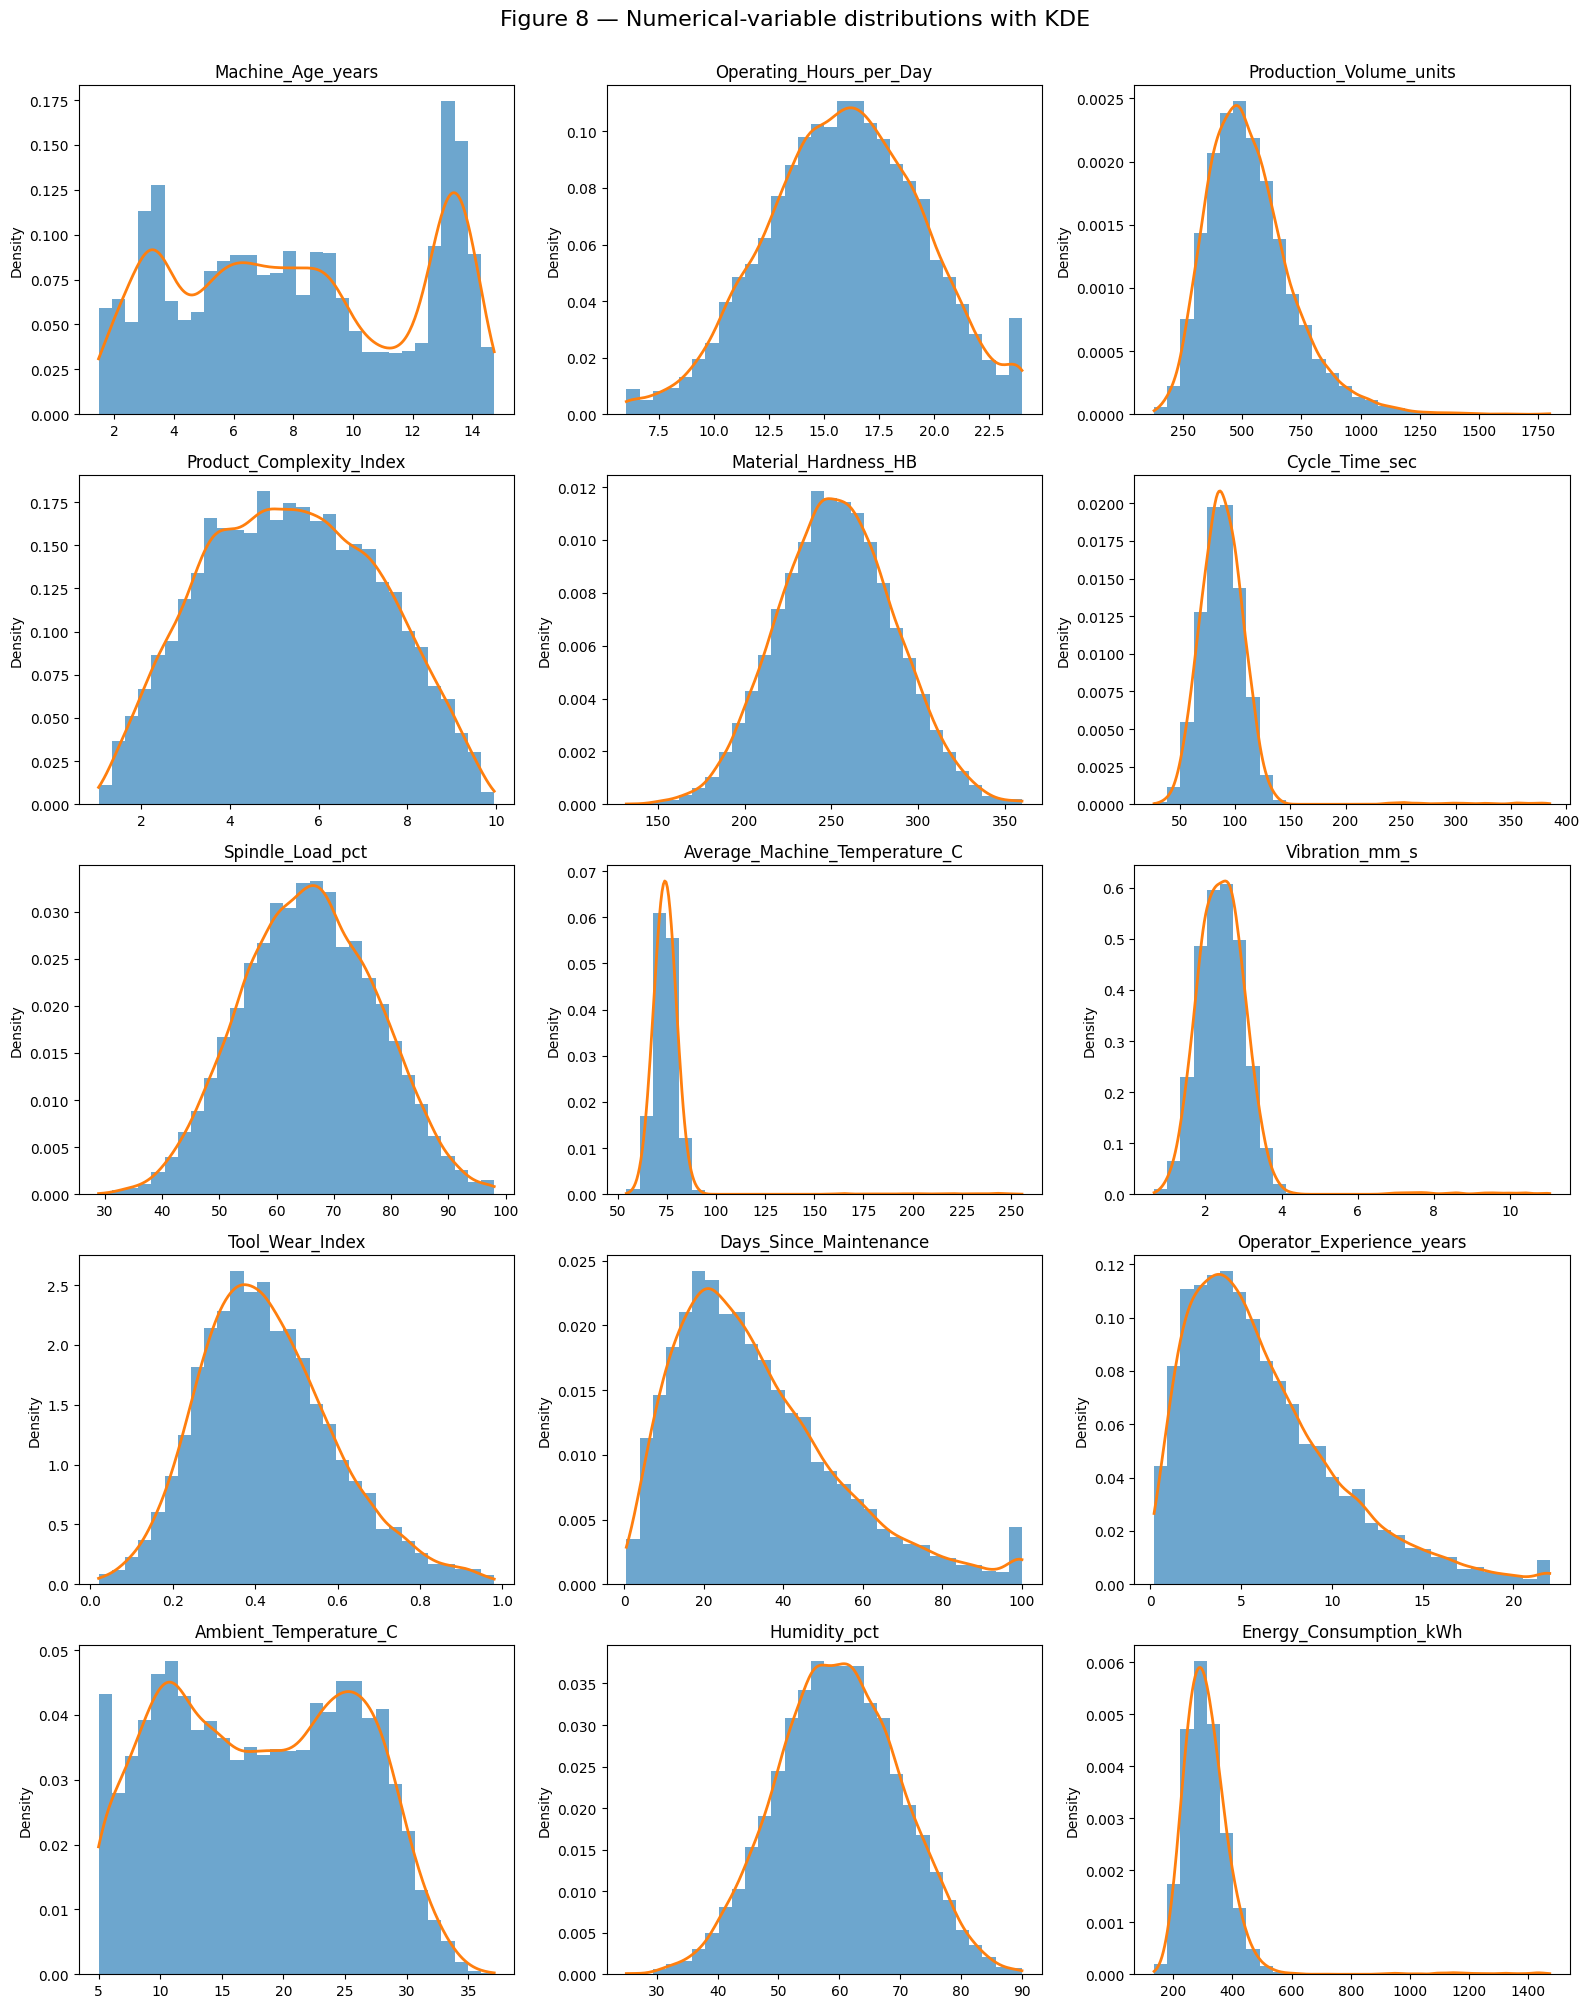

In [42]:
# Histograms + KDE for all numeric analytical variables.
from scipy.stats import gaussian_kde

ncols = 3
nrows = math.ceil(len(analysis_numeric_cols) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.0 * nrows))
axes = np.asarray(axes).ravel()

for ax, col in zip(axes, analysis_numeric_cols):
    values = df[col].dropna().to_numpy()
    ax.hist(values, bins=30, alpha=0.65, density=True)
    if len(values) > 10 and np.nanstd(values) > 0:
        x_grid = np.linspace(values.min(), values.max(), 300)
        kde = gaussian_kde(values)
        ax.plot(x_grid, kde(x_grid), linewidth=2)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Density")

for ax in axes[len(analysis_numeric_cols):]:
    ax.remove()

fig.suptitle("Figure 8 — Numerical-variable distributions with KDE", y=1.002, fontsize=16)
plt.tight_layout()
save_and_show("Figure_08_Numerical_Variable_Distributions_with_KDE.png")


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots/Figure_09_Numerical_Variable_Box_Plots.png


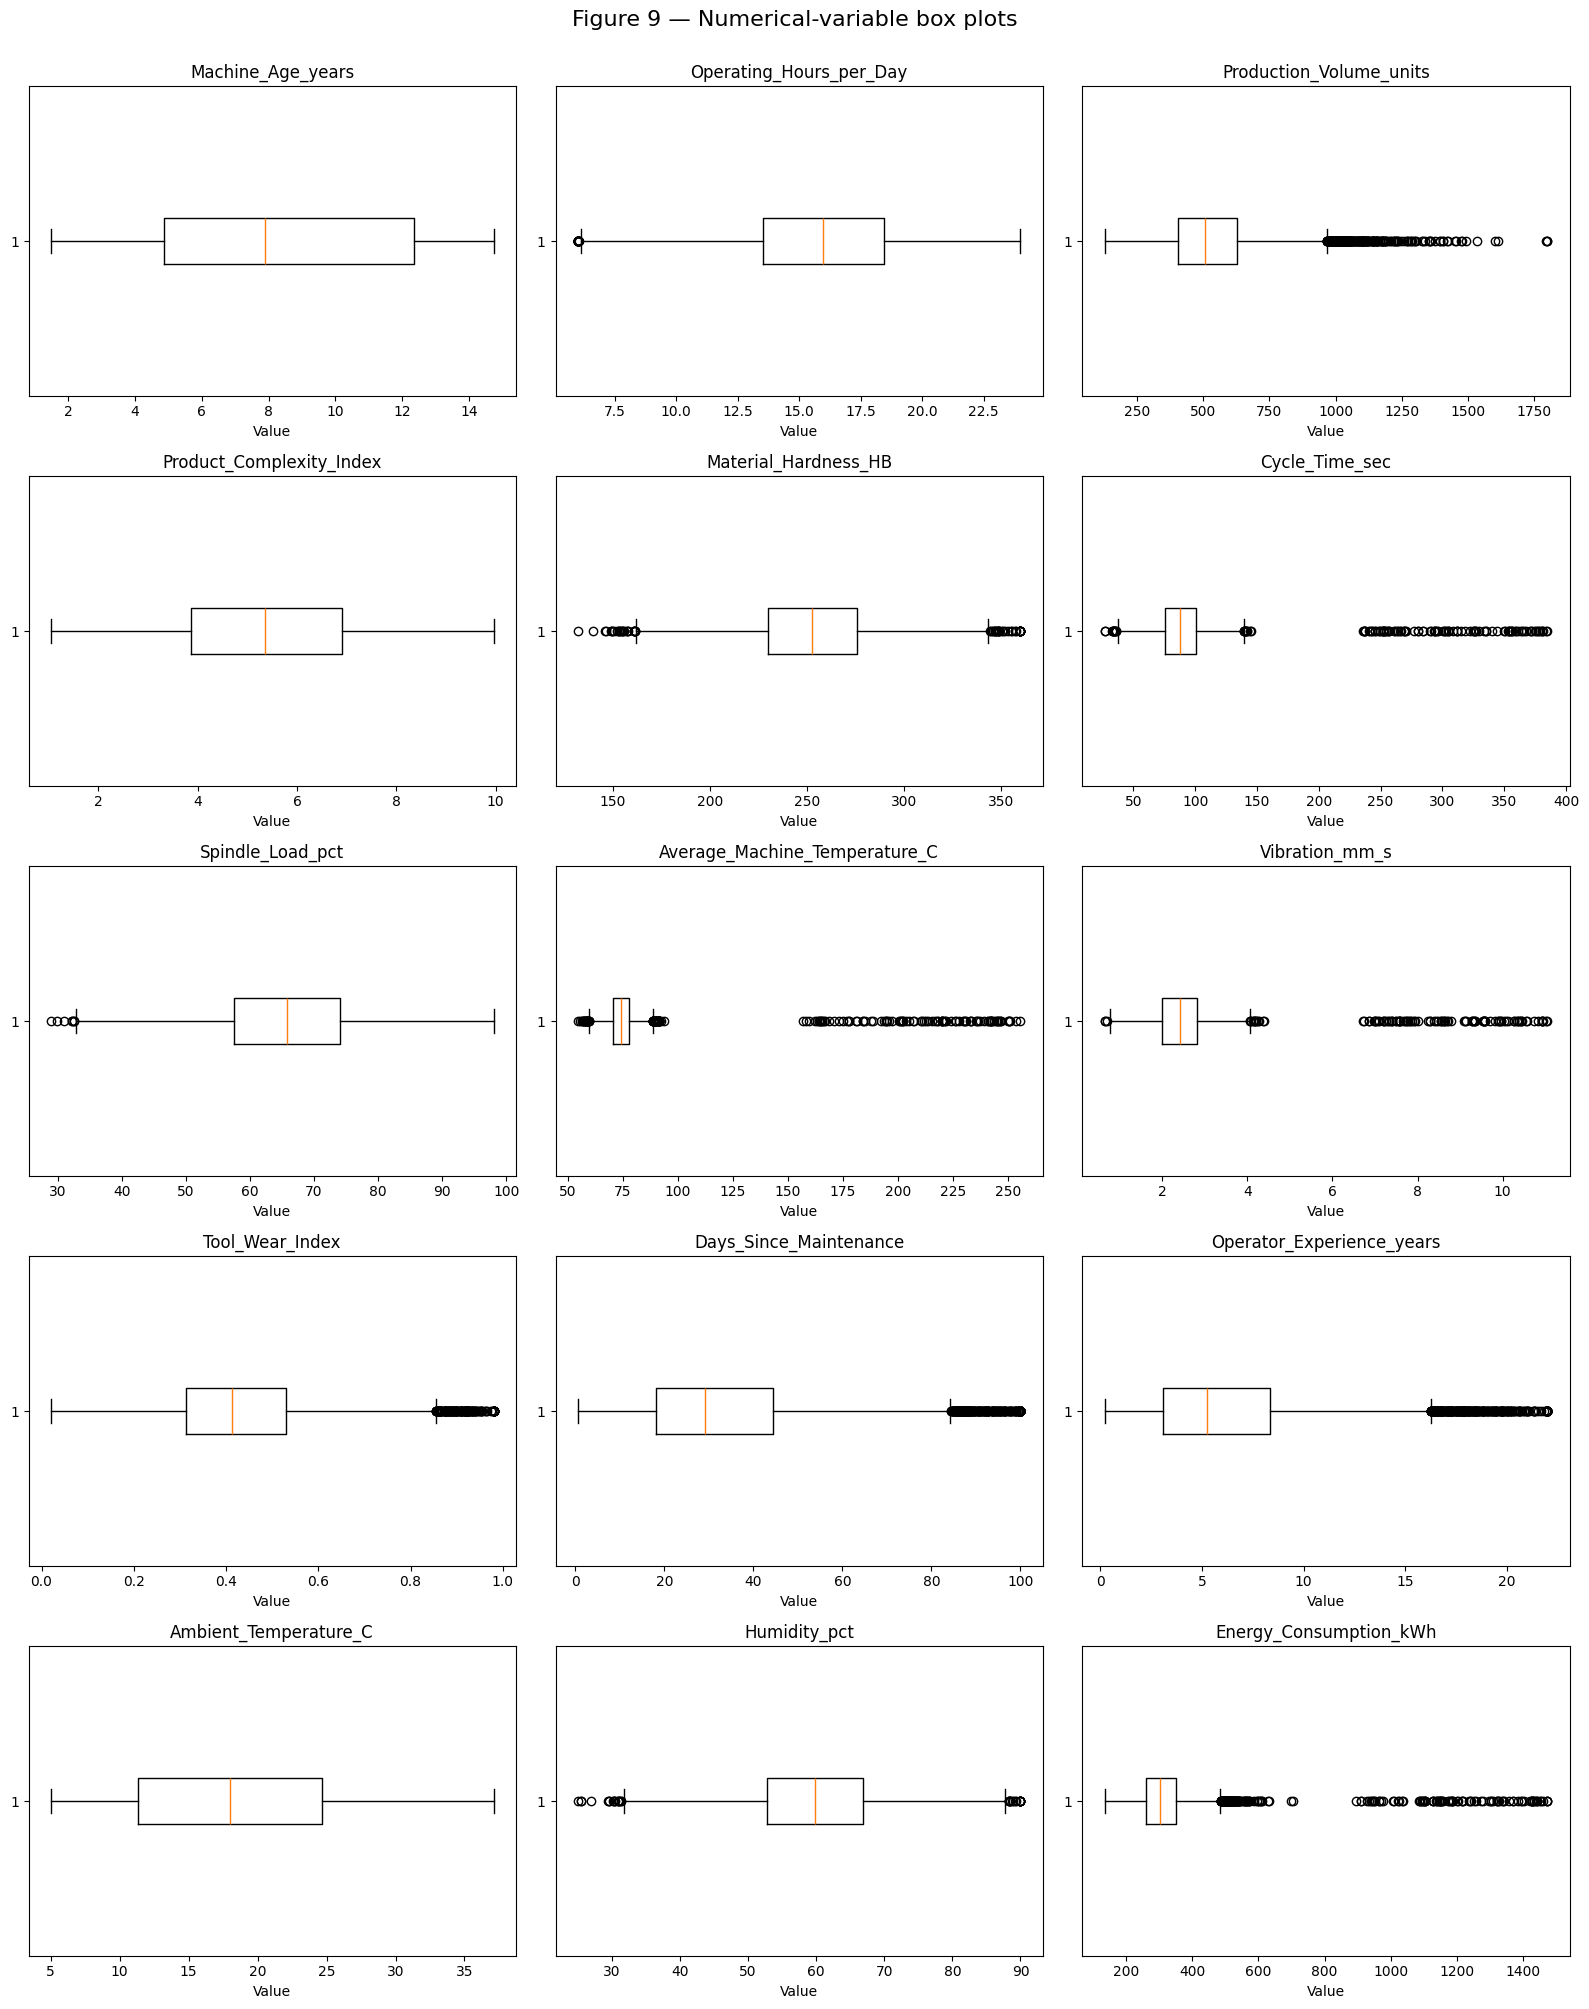

In [43]:
# Box plots for all numerical variables using independent panels.
ncols = 3
nrows = math.ceil(len(analysis_numeric_cols) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.0 * nrows))
axes = np.asarray(axes).ravel()

for ax, col in zip(axes, analysis_numeric_cols):
    values = df[col].dropna().to_numpy()
    ax.boxplot(values, vert=False)
    ax.set_title(col)
    ax.set_xlabel("Value")

for ax in axes[len(analysis_numeric_cols):]:
    ax.remove()

fig.suptitle("Figure 9 — Numerical-variable box plots", y=1.002, fontsize=16)
plt.tight_layout()
save_and_show("Figure_09_Numerical_Variable_Box_Plots.png")


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots/Figure_10_Violin_Plots_Scenario_Critical_Variables.png


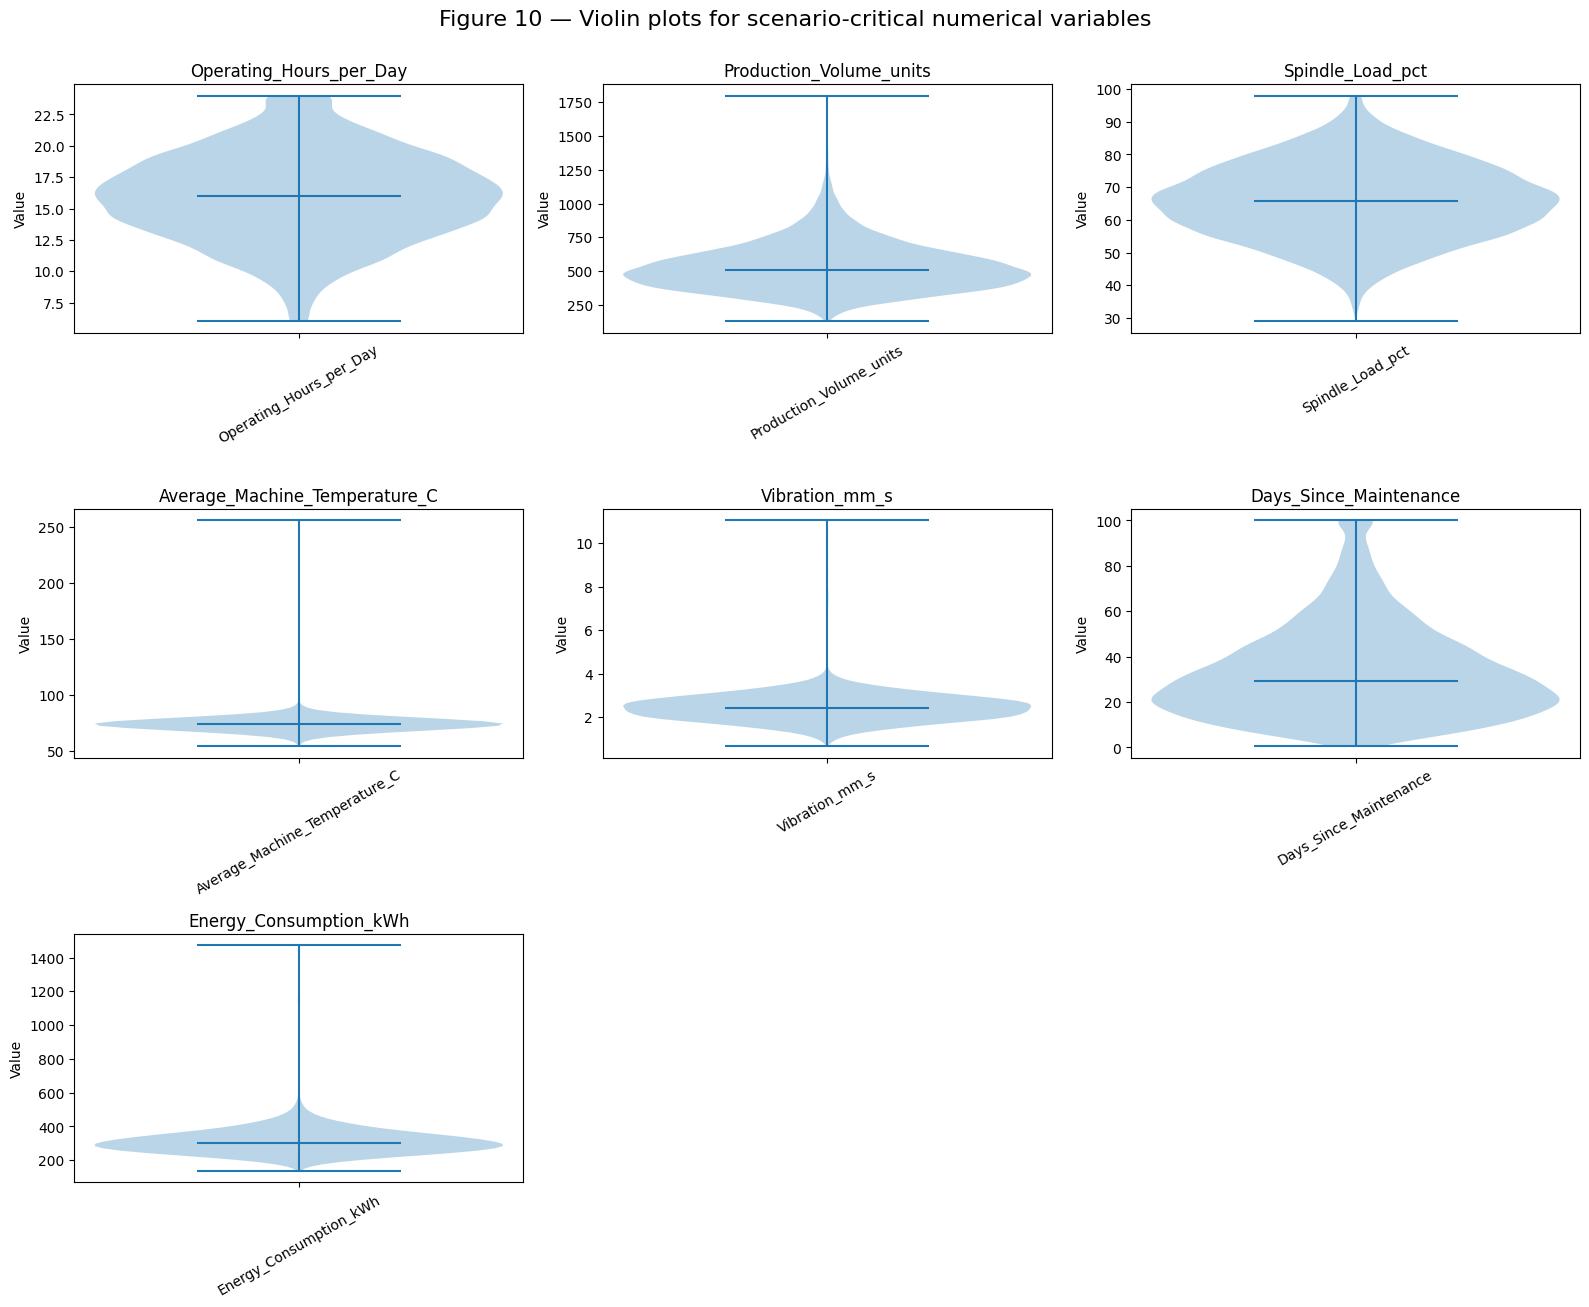

In [44]:
# Focused violin plots for scenario-critical variables.
violin_cols = [
    "Operating_Hours_per_Day",
    "Production_Volume_units",
    "Spindle_Load_pct",
    "Average_Machine_Temperature_C",
    "Vibration_mm_s",
    "Days_Since_Maintenance",
    TARGET
]

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.ravel()

for ax, col in zip(axes, violin_cols):
    values = df[col].dropna().to_numpy()
    ax.violinplot(values, vert=True, showmedians=True)
    ax.set_title(col)
    ax.set_ylabel("Value")
    ax.set_xticks([1])
    ax.set_xticklabels([col], rotation=30)

for ax in axes[len(violin_cols):]:
    ax.remove()

fig.suptitle("Figure 10 — Violin plots for scenario-critical numerical variables", y=1.002, fontsize=16)
plt.tight_layout()
save_and_show("Figure_10_Violin_Plots_Scenario_Critical_Variables.png")


### Numerical distribution observations

The numerical plots should be read together rather than independently. In particular:

1. The target and several process variables show non-normal or heavy-tailed behavior.
2. `Average_Machine_Temperature_C`, `Cycle_Time_sec`, `Production_Volume_units`, `Operator_Experience_years`, and other variables exhibit visible tail behavior that merits investigation.
3. The project brief explicitly warns about nonlinear behavior. Therefore, a simple Pearson correlation or a linear trend alone should not be treated as a complete description of the data-generating relationships.


# 7. Outlier detection

The project rubric explicitly assigns marks to outlier detection. We use the **1.5 × IQR rule** as a transparent screening method and report the number and percentage of observations beyond the inner fences.

This is an **outlier flag**, not an automatic deletion rule. NIST emphasizes that unusual observations should be investigated because they may represent either data problems or meaningful process behavior.


In [45]:
outlier_records = []

for col in analysis_numeric_cols:
    s = df[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (s < lower) | (s > upper)

    outlier_records.append({
        "feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_fence": lower,
        "upper_fence": upper,
        "outlier_count": int(mask.sum()),
        "outlier_pct": float(mask.mean() * 100)
    })

outlier_table = pd.DataFrame(outlier_records).sort_values(
    "outlier_count", ascending=False
).reset_index(drop=True)

display(outlier_table.round(3))


,feature,Q1,Q3,IQR,lower_fence,upper_fence,outlier_count,outlier_pct
0,Operator_Experience_years,3.060,8.340,5.280,-4.860,16.260,329,3.210
1,Days_Since_Maintenance,18.000,44.500,26.500,-21.750,84.250,307,2.995
2,Production_Volume_units,404.000,629.000,225.000,66.500,966.500,257,2.507
3,Energy_Consumption_kWh,260.695,350.510,89.815,125.972,485.232,223,2.266
4,Average_Machine_Temperature_C,70.460,77.695,7.235,59.607,88.547,166,1.687
5,Tool_Wear_Index,0.313,0.530,0.217,-0.013,0.856,148,1.536
6,Cycle_Time_sec,75.272,100.790,25.518,36.996,139.066,125,1.220
7,Vibration_mm_s,1.995,2.823,0.828,0.753,4.065,113,1.160
8,Material_Hardness_HB,230.100,275.800,45.700,161.550,344.350,59,0.576
9,Operating_Hours_per_Day,13.530,18.468,4.938,6.124,25.874,42,0.410


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots/Figure_11_IQR_Based_Outlier_Counts.png


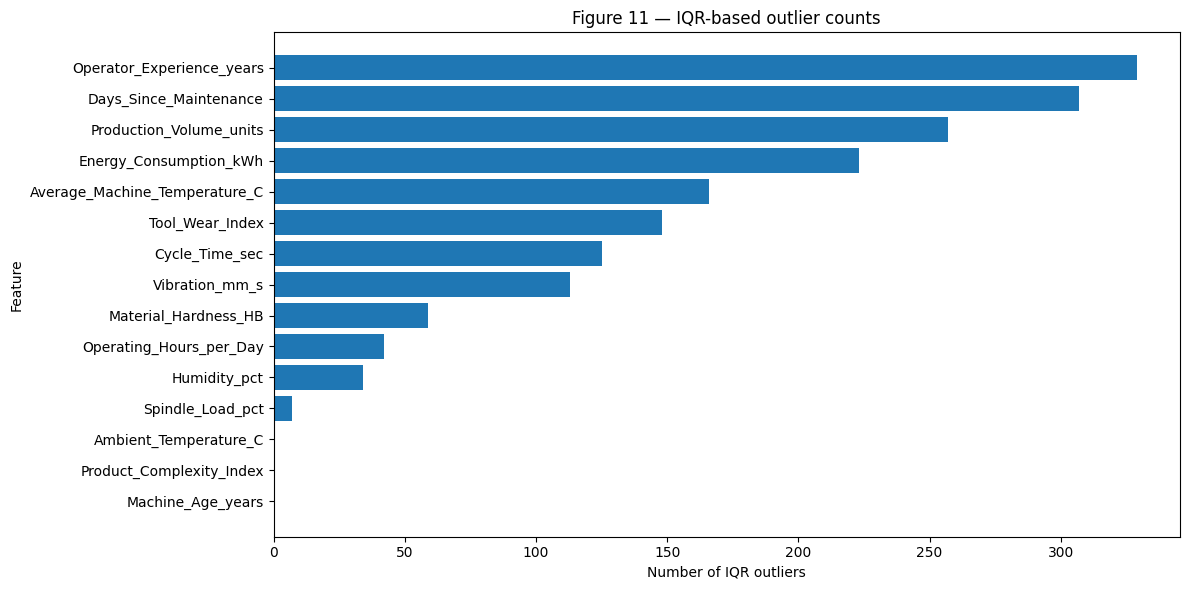

In [46]:
# Outlier counts by numerical feature.
plt.figure(figsize=(12, 6))
plot_df = outlier_table.sort_values("outlier_count")
plt.barh(plot_df["feature"], plot_df["outlier_count"])
plt.xlabel("Number of IQR outliers")
plt.ylabel("Feature")
plt.title("Figure 11 — IQR-based outlier counts")
plt.tight_layout()
save_and_show("Figure_11_IQR_Based_Outlier_Counts.png")

In [47]:
# Target-focused outlier inspection.
q1 = df[TARGET].quantile(0.25)
q3 = df[TARGET].quantile(0.75)
iqr = q3 - q1
target_lower = q1 - 1.5 * iqr
target_upper = q3 + 1.5 * iqr

target_outliers = df[
    (df[TARGET] < target_lower) | (df[TARGET] > target_upper)
][[
    ID_COL, "Machine_ID", "Machine_Type", "Shift",
    "Operating_Hours_per_Day", "Production_Volume_units",
    "Product_Complexity_Index", "Spindle_Load_pct",
    "Average_Machine_Temperature_C", "Vibration_mm_s",
    "Tool_Wear_Index", "Days_Since_Maintenance", TARGET
]].sort_values(TARGET, ascending=False)

print(f"Target Q1 = {q1:.2f}")
print(f"Target Q3 = {q3:.2f}")
print(f"Target IQR = {iqr:.2f}")
print(f"Target lower fence = {target_lower:.2f}")
print(f"Target upper fence = {target_upper:.2f}")
print(f"Target outliers = {len(target_outliers)} ({len(target_outliers)/df[TARGET].notna().sum()*100:.2f}% of observed target values)")

display(target_outliers.head(15))


Target Q1 = 260.69
Target Q3 = 350.51
Target IQR = 89.81
Target lower fence = 125.97
Target upper fence = 485.23
Target outliers = 223 (2.27% of observed target values)


,Observation_ID,Machine_ID,Machine_Type,Shift,Operating_Hours_per_Day,Production_Volume_units,Product_Complexity_Index,Spindle_Load_pct,Average_Machine_Temperature_C,Vibration_mm_s,Tool_Wear_Index,Days_Since_Maintenance,Energy_Consumption_kWh
2453,2454,M006,Laser_Cutter,Day,21.190,834,4.250,68.760,74.590,2.239,0.315,19.800,"1,472.820"
7672,7673,M034,CNC_Grinder,Evening,16.570,379,3.200,53.460,72.680,1.029,0.202,22.200,"1,470.960"
212,213,M019,CNC_Mill,Night,15.760,500,4.720,64.650,68.070,3.441,0.462,29.300,"1,470.300"
2265,2266,M027,CNC_Mill,Day,11.180,338,6.270,80.450,72.700,3.337,0.431,57.200,"1,460.520"
7231,7232,M044,CNC_Lathe,Day,15.530,656,3.910,62.230,74.560,2.000,0.343,23.600,"1,454.450"
9991,9992,M039,Laser_Cutter,Night,13.240,526,4.370,52.600,67.790,1.598,0.181,16.700,"1,449.210"
4540,4541,M035,CNC_Grinder,Evening,14.310,484,4.890,58.510,71.180,2.032,0.411,32.800,"1,442.570"
6068,6069,M029,CNC_Mill,Day,23.060,792,3.470,51.470,69.670,1.777,0.397,26.500,"1,441.090"
1723,1724,M005,CNC_Mill,Day,14.880,377,5.620,52.560,73.020,2.487,0.485,27.400,"1,437.430"
1026,1027,M037,Laser_Cutter,Day,14.540,560,6.120,61.120,64.510,2.167,0.199,13.000,"1,433.720"


### Outlier interpretation

The IQR screen identifies potential outliers in both predictors and the target. Particularly important are the high-end observations of energy consumption and the extreme values of machine temperature, cycle time, production volume, operator experience, and days since maintenance.

Because the project scenario is specifically interested in **unusually high energy use**, high target values should not be discarded merely because they are statistically unusual. They may represent the operational situations that management most wants to understand.


# 8. Relationships among variables

This section addresses the rubric's relationship-analysis criterion using:

- correlation heatmap,
- pair plot,
- parallel-coordinate plot,
- bubble/scatter plot,
- and targeted group comparisons.

The goal is not only to find large correlations but to test whether the relationships suggested by the project scenario are consistent with the observed data.


In [48]:
# Pearson correlation with the target.
target_corr = (
    df[analysis_numeric_cols]
    .corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(target_corr.to_frame("Pearson_r_with_target"))


,Pearson_r_with_target
Product_Complexity_Index,0.342
Spindle_Load_pct,0.330
Tool_Wear_Index,0.293
Material_Hardness_HB,0.254
Operating_Hours_per_Day,0.220
Days_Since_Maintenance,0.199
Vibration_mm_s,0.189
Ambient_Temperature_C,-0.155
Cycle_Time_sec,0.124
Average_Machine_Temperature_C,0.123


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots/Figure_12_Correlation_Heatmap.png


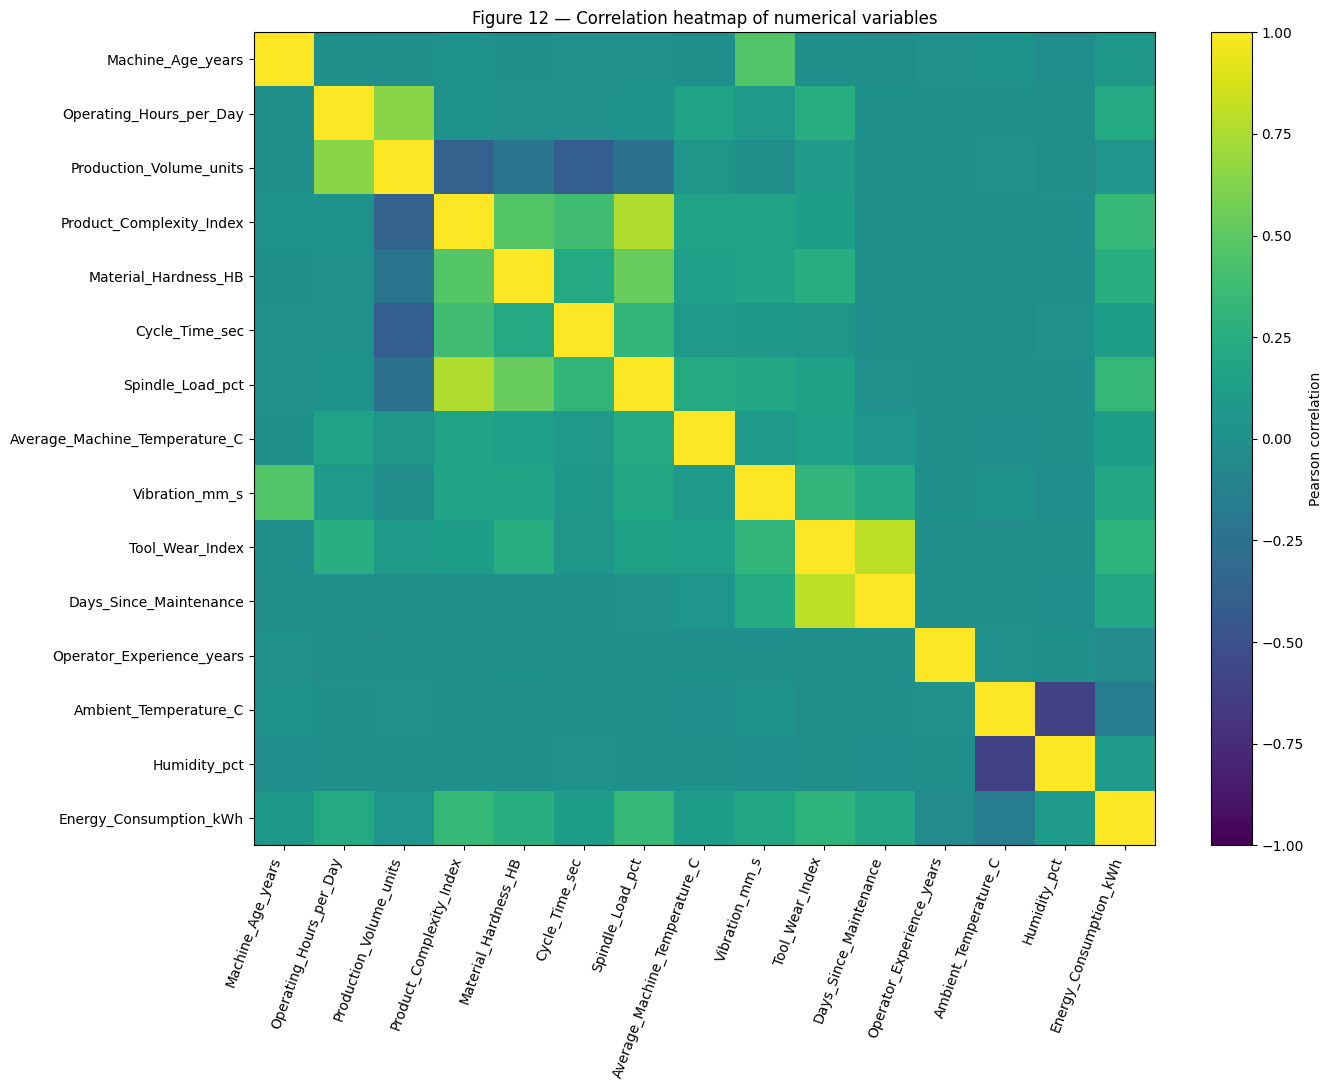

In [49]:
# Correlation heatmap.
corr_matrix = df[analysis_numeric_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(14, 11))
im = ax.imshow(corr_matrix.values, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.index)))
ax.set_xticklabels(corr_matrix.columns, rotation=70, ha="right")
ax.set_yticklabels(corr_matrix.index)
ax.set_title("Figure 12 — Correlation heatmap of numerical variables")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
save_and_show("Figure_12_Correlation_Heatmap.png")


### Correlation interpretation

The target correlations provide a useful first screening, but they should not be interpreted as proof of causation. For example, the strongest absolute Pearson relationships with energy consumption in the supplied data are associated with variables such as product complexity, spindle load, tool wear, material hardness, operating hours, and days since maintenance. Ambient temperature has a negative linear association with the target in this raw dataset.

The project brief's explicit warning about nonlinearities makes it especially important to complement the heatmap with scatter plots and grouped/binned analyses.


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots/Figure_13_Pair_Plot_Scatter_Matrix.png


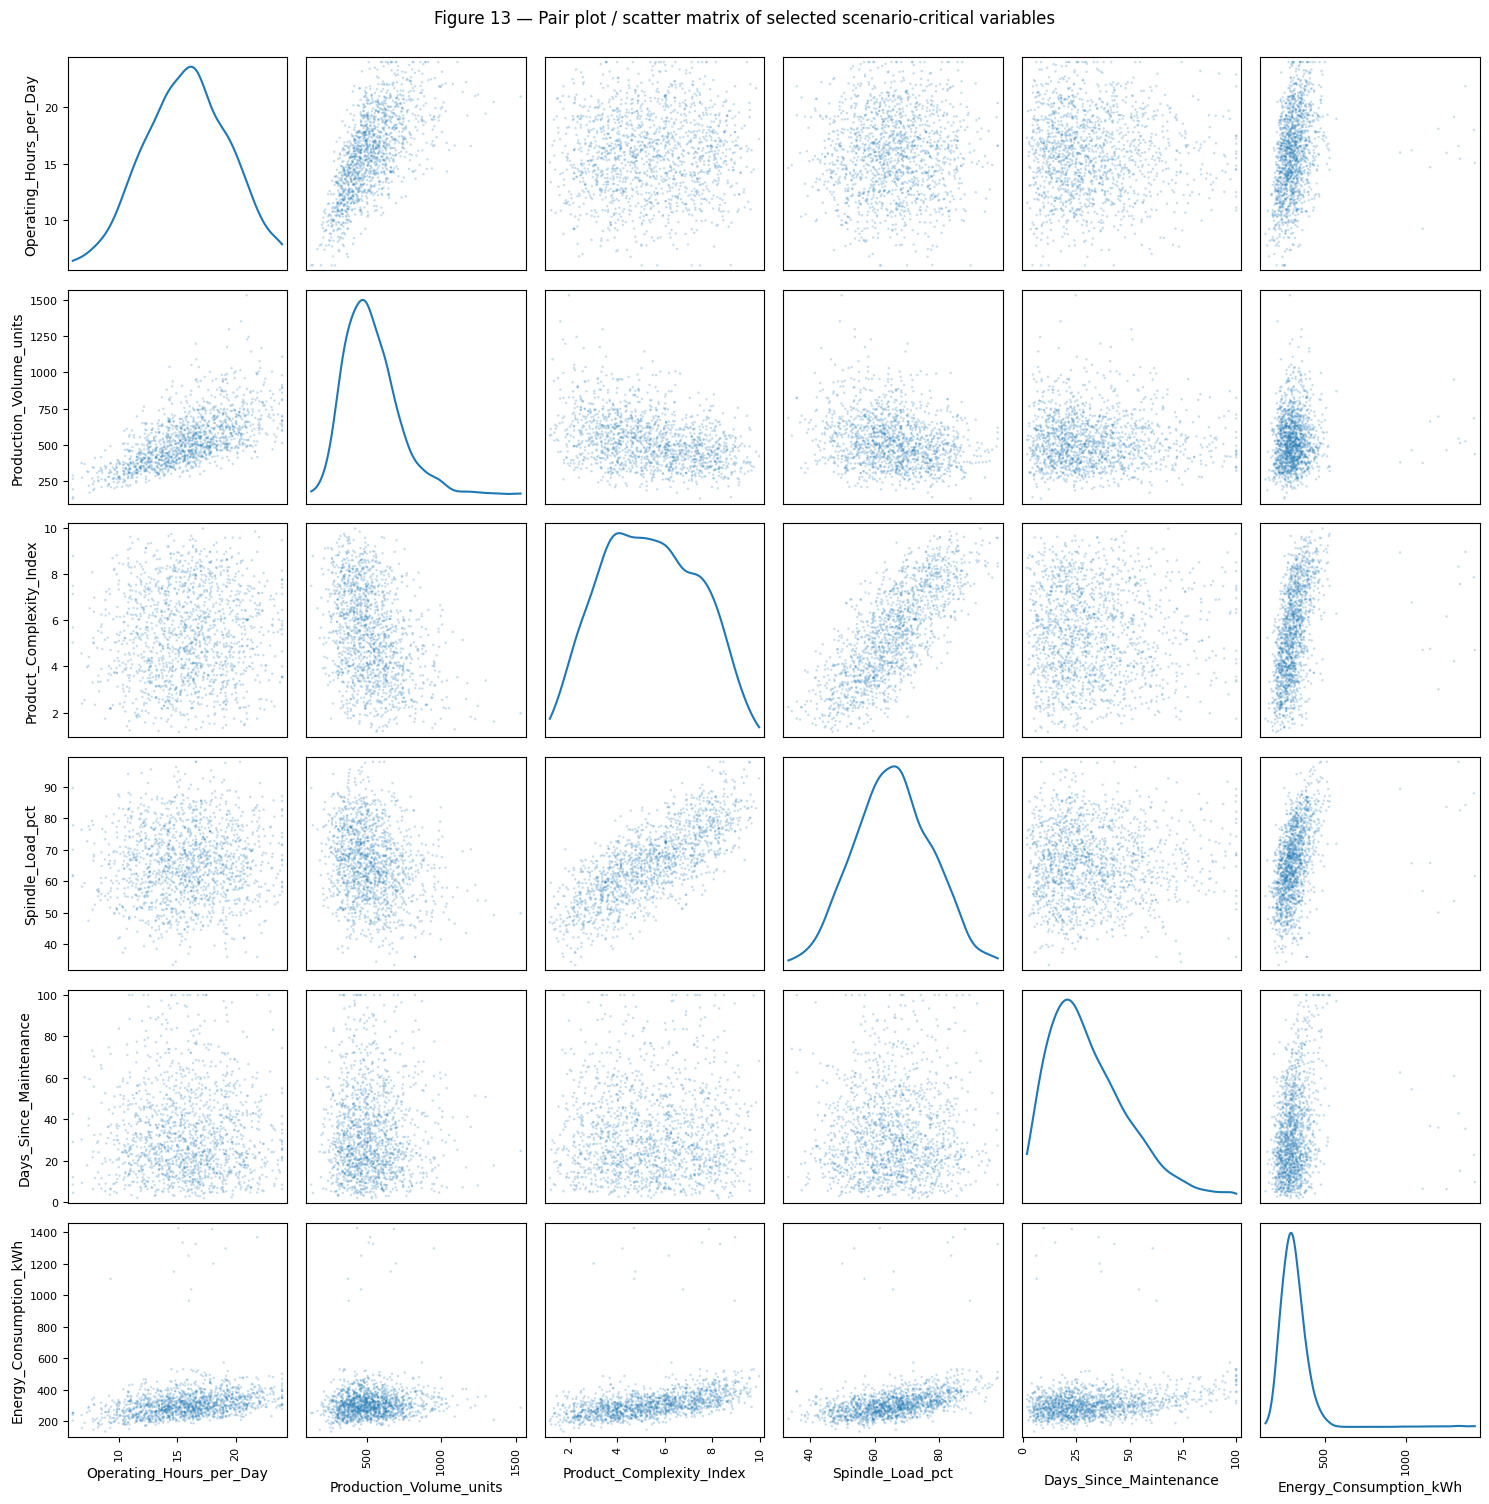

In [50]:
# Pair-plot equivalent: scatter matrix on a reproducible sample.
pair_cols = [
    "Operating_Hours_per_Day",
    "Production_Volume_units",
    "Product_Complexity_Index",
    "Spindle_Load_pct",
    "Days_Since_Maintenance",
    TARGET
]

pair_sample = (
    df[pair_cols]
    .dropna()
    .sample(n=min(1500, df[pair_cols].dropna().shape[0]), random_state=RANDOM_STATE)
)

axes = pd.plotting.scatter_matrix(
    pair_sample,
    figsize=(15, 15),
    diagonal="kde",
    alpha=0.25,
    s=12
)
plt.suptitle("Figure 13 — Pair plot / scatter matrix of selected scenario-critical variables", y=1.0)
plt.tight_layout()
save_and_show("Figure_13_Pair_Plot_Scatter_Matrix.png")


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots/Figure_14_Bubble_Chart_Production_Intensity_and_Energy.png


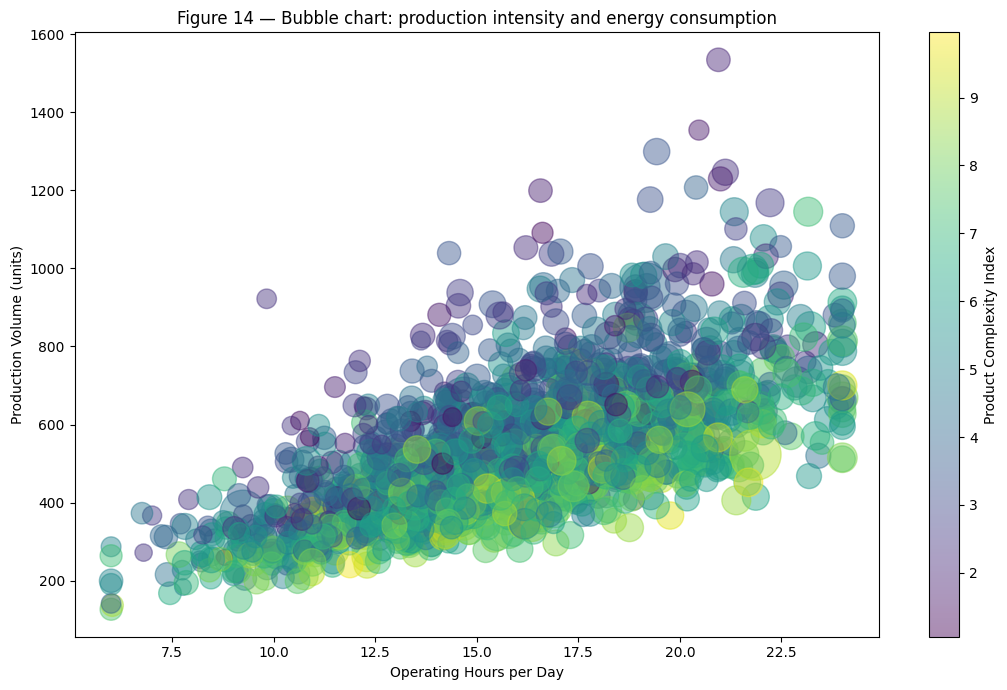

In [51]:
# Bubble chart: operating hours vs production volume, bubble size = target energy.
bubble_df = df[[
    "Operating_Hours_per_Day",
    "Production_Volume_units",
    "Product_Complexity_Index",
    TARGET
]].dropna().sample(
    n=min(1800, df[[
        "Operating_Hours_per_Day",
        "Production_Volume_units",
        "Product_Complexity_Index",
        TARGET
    ]].dropna().shape[0]),
    random_state=RANDOM_STATE
)

plt.figure(figsize=(11, 7))
sizes = np.clip(bubble_df[TARGET], 20, None)
plt.scatter(
    bubble_df["Operating_Hours_per_Day"],
    bubble_df["Production_Volume_units"],
    s=sizes,
    c=bubble_df["Product_Complexity_Index"],
    alpha=0.45,
    cmap="viridis"
)
plt.colorbar(label="Product Complexity Index")
plt.xlabel("Operating Hours per Day")
plt.ylabel("Production Volume (units)")
plt.title("Figure 14 — Bubble chart: production intensity and energy consumption")
plt.tight_layout()
save_and_show("Figure_14_Bubble_Chart_Production_Intensity_and_Energy.png")


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots/Figure_15_Parallel_Coordinates.png


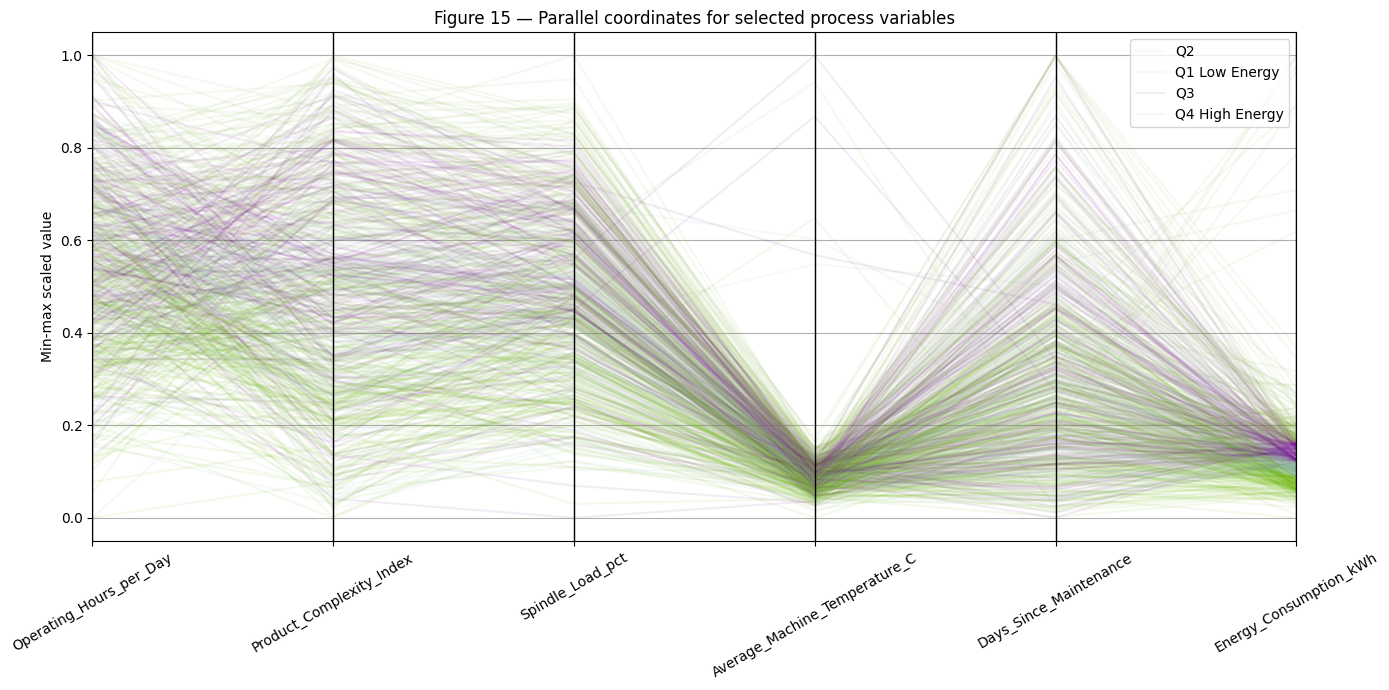

In [52]:
# Parallel coordinates: normalize selected variables for visual comparability.
parallel_cols = [
    "Operating_Hours_per_Day",
    "Product_Complexity_Index",
    "Spindle_Load_pct",
    "Average_Machine_Temperature_C",
    "Days_Since_Maintenance",
    TARGET
]

pc = df[parallel_cols].dropna().copy()
pc = pc.sample(n=min(600, len(pc)), random_state=RANDOM_STATE)

# Convert each variable to a 0-1 scale so different units can be compared.
pc_scaled = pc.copy()
for col in parallel_cols:
    lo, hi = pc_scaled[col].min(), pc_scaled[col].max()
    pc_scaled[col] = (pc_scaled[col] - lo) / (hi - lo) if hi > lo else 0

# Discretize target into quartile classes solely for visual grouping.
pc_scaled["Energy_Group"] = pd.qcut(
    pc[TARGET], q=4,
    labels=["Q1 Low Energy", "Q2", "Q3", "Q4 High Energy"],
    duplicates="drop"
)

plt.figure(figsize=(14, 7))
parallel_coordinates(
    pc_scaled,
    "Energy_Group",
    alpha=0.08
)
plt.title("Figure 15 — Parallel coordinates for selected process variables")
plt.ylabel("Min-max scaled value")
plt.xticks(rotation=30)
plt.tight_layout()
save_and_show("Figure_15_Parallel_Coordinates.png")



# 9. Target-oriented nonlinear pattern investigation

The project brief explicitly states that the data intentionally contains nonlinear patterns such as overload and overheating thresholds, U-shaped operating regions, diminishing returns, and interactions. The following analyses therefore use **binned target means** and focused scatter plots rather than relying only on linear correlation.


In [53]:
def binned_target_summary(column, bins):
    tmp = df[[column, TARGET]].dropna().copy()
    tmp["bin"] = pd.cut(tmp[column], bins=bins, include_lowest=True)
    return tmp.groupby("bin", observed=False)[TARGET].agg(
        count="count",
        mean="mean",
        median="median"
    )

bin_specs = {
    "Spindle_Load_pct": [0, 40, 60, 70, 80, 90, 100],
    "Average_Machine_Temperature_C": [0, 60, 70, 80, 90, 100, 120, 160, 220, 300],
    "Cycle_Time_sec": [0, 60, 80, 100, 120, 160, 220, 400],
    "Days_Since_Maintenance": [0, 15, 30, 45, 60, 80, 100],
    "Operator_Experience_years": [0, 2, 5, 8, 12, 16, 25],
    "Production_Volume_units": [0, 300, 500, 700, 900, 1200, 1800]
}

for col, bins in bin_specs.items():
    print(f"\n{col}")
    display(binned_target_summary(col, bins).round(2))



Spindle_Load_pct


,count,mean,median
bin,,,
"(-0.001, 40.0]",93,269.360,255.970
"(40.0, 60.0]",3060,281.790,269.920
"(60.0, 70.0]",3185,305.300,291.940
"(70.0, 80.0]",2336,341.680,328.660
"(80.0, 90.0]",1009,385.750,372.350
"(90.0, 100.0]",156,463.760,433.000



Average_Machine_Temperature_C


,count,mean,median
bin,,,
"(-0.001, 60.0]",38,231.070,239.490
"(60.0, 70.0]",2071,271.570,257.170
"(70.0, 80.0]",6022,319.420,305.440
"(80.0, 90.0]",1202,383.890,371.240
"(90.0, 100.0]",17,511.350,518.040
"(100.0, 120.0]",0,NaN,NaN
"(120.0, 160.0]",3,399.610,411.640
"(160.0, 220.0]",48,333.710,310.580
"(220.0, 300.0]",42,314.730,313.590



Cycle_Time_sec


...

,count,mean,median
bin,,,
"(-0.001, 15.0]",1832,299.380,282.270
"(15.0, 30.0]",3293,305.510,292.290
"(30.0, 45.0]",2336,316.000,301.860
"(45.0, 60.0]",1278,323.670,312.070
"(60.0, 80.0]",729,358.140,342.380
"(80.0, 100.0]",371,409.880,395.390



Operator_Experience_years


,count,mean,median
bin,,,
"(-0.001, 2.0]",1267,321.240,308.640
"(2.0, 5.0]",3371,319.890,304.680
"(5.0, 8.0]",2518,318.130,302.880
"(8.0, 12.0]",1693,310.840,296.990
"(12.0, 16.0]",644,308.580,294.280
"(16.0, 25.0]",346,312.390,293.680



Production_Volume_units


,count,mean,median
bin,,,
"(-0.001, 300.0]",640,298.670,288.790
"(300.0, 500.0]",4123,316.960,301.300
"(500.0, 700.0]",3533,316.630,301.780
"(700.0, 900.0]",1158,322.330,305.130
"(900.0, 1200.0]",341,337.290,322.030
"(1200.0, 1800.0]",44,330.460,322.550


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots/Figure_16_Binned_Target_Means_Threshold_Behavior.png


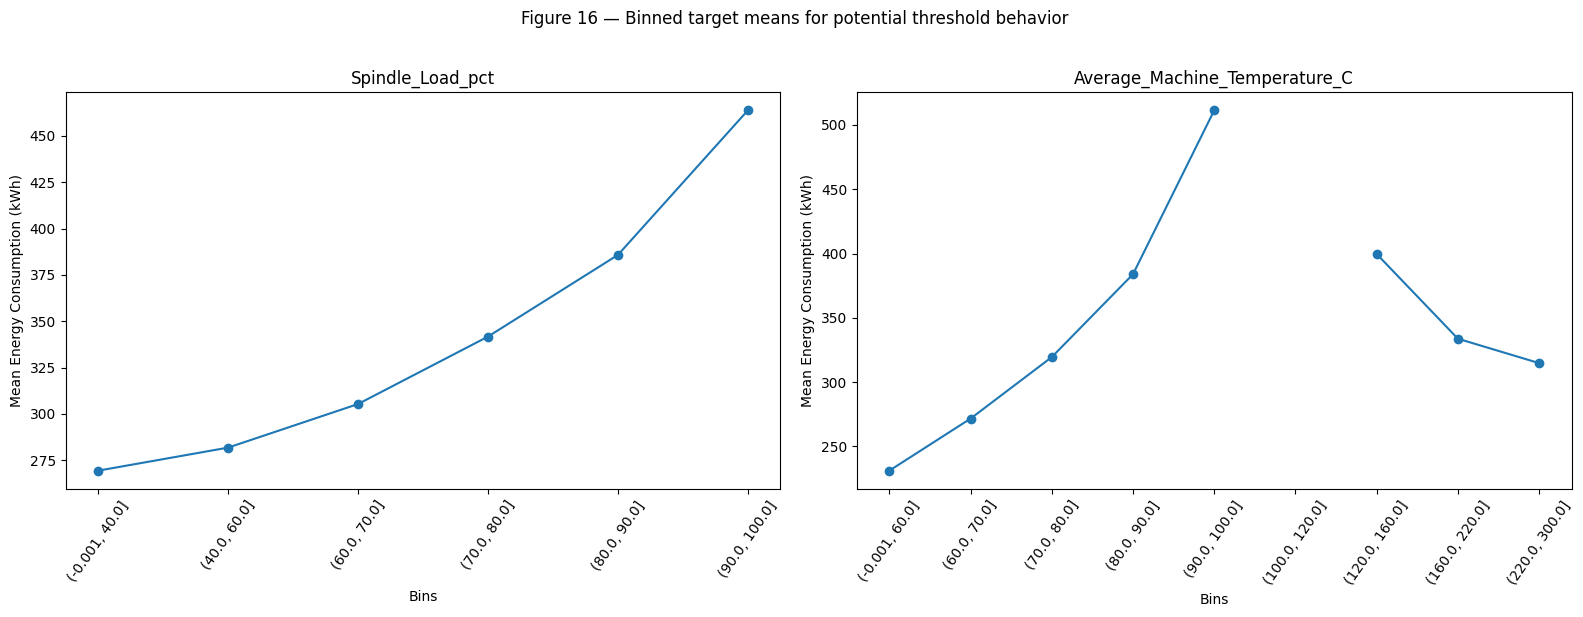

In [54]:
# Target mean by spindle load and temperature bins.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, col, bins in [
    (axes[0], "Spindle_Load_pct", bin_specs["Spindle_Load_pct"]),
    (axes[1], "Average_Machine_Temperature_C", bin_specs["Average_Machine_Temperature_C"])
]:
    summary = binned_target_summary(col, bins)
    labels = [str(x) for x in summary.index]
    ax.plot(labels, summary["mean"], marker="o")
    ax.set_title(col)
    ax.set_xlabel("Bins")
    ax.set_ylabel("Mean Energy Consumption (kWh)")
    ax.tick_params(axis="x", rotation=55)

fig.suptitle("Figure 16 — Binned target means for potential threshold behavior", y=1.02)
plt.tight_layout()
save_and_show("Figure_16_Binned_Target_Means_Threshold_Behavior.png")


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots/Figure_17_Nonlinear_Trend_Screening_LOWESS.png


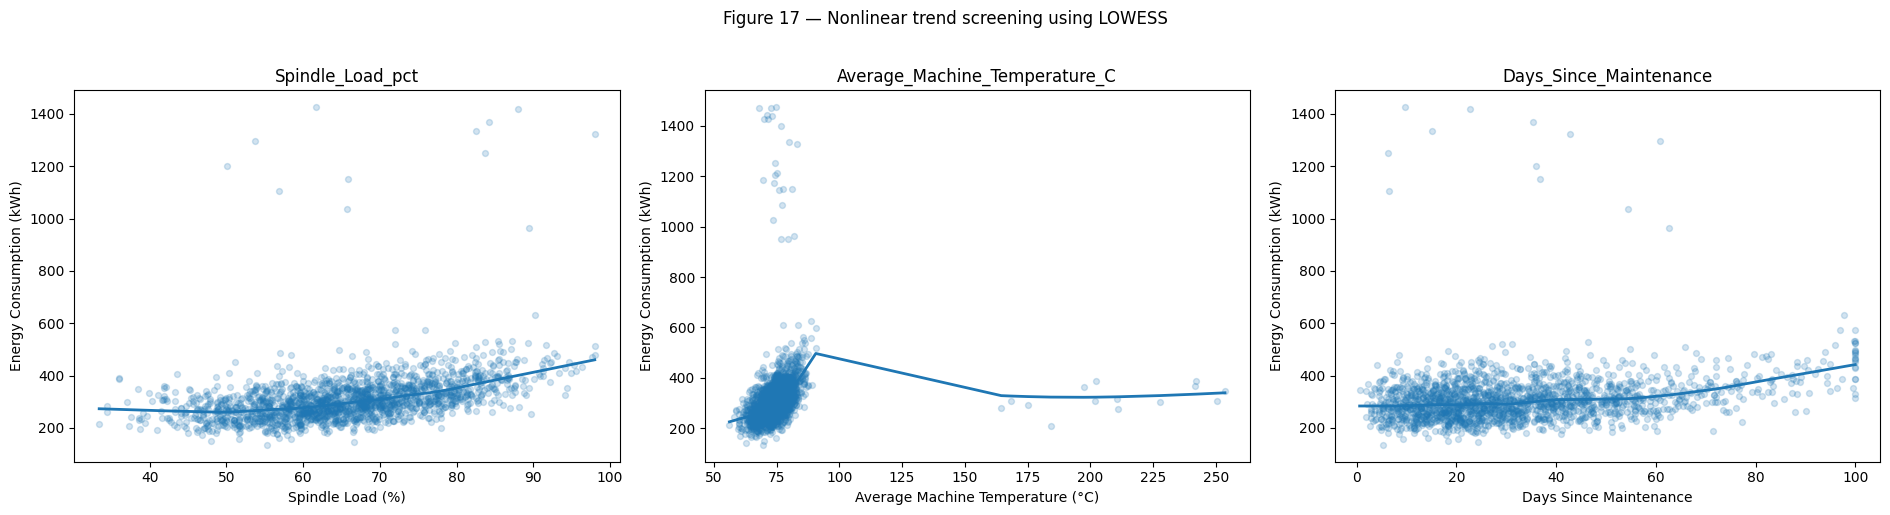

In [55]:
# Direct scatter plots with LOWESS trend lines.
from statsmodels.nonparametric.smoothers_lowess import lowess

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

scatter_specs = [
    ("Spindle_Load_pct", "Spindle Load (%)"),
    ("Average_Machine_Temperature_C", "Average Machine Temperature (°C)"),
    ("Days_Since_Maintenance", "Days Since Maintenance")
]

for ax, (col, label) in zip(axes, scatter_specs):
    sample = df[[col, TARGET]].dropna().sample(
        n=min(1800, df[[col, TARGET]].dropna().shape[0]),
        random_state=RANDOM_STATE
    )
    x = sample[col].to_numpy()
    y = sample[TARGET].to_numpy()
    ax.scatter(x, y, alpha=0.20, s=18)
    order = np.argsort(x)
    smooth = lowess(y[order], x[order], frac=0.25, return_sorted=True)
    ax.plot(smooth[:, 0], smooth[:, 1], linewidth=2)
    ax.set_xlabel(label)
    ax.set_ylabel("Energy Consumption (kWh)")
    ax.set_title(col)

fig.suptitle("Figure 17 — Nonlinear trend screening using LOWESS", y=1.02)
plt.tight_layout()
save_and_show("Figure_17_Nonlinear_Trend_Screening_LOWESS.png")


### Nonlinear-pattern interpretation

The binned summaries and LOWESS plots are deliberately included because the project brief warns that relationships may not be linear. In the supplied data:

- **Spindle load:** mean energy rises markedly across higher load bands, especially toward the upper end.
- **Temperature:** energy rises through the main operating range, while a small number of extreme temperature observations create a separate tail that should be investigated rather than automatically treated as a normal operating regime.
- **Days since maintenance:** mean energy generally increases as the time since maintenance becomes longer, with a particularly elevated mean in the highest maintenance-delay bands.
- **Cycle time and operating conditions:** the relationship should be interpreted from the shape of the LOWESS curve and binned means rather than from a single correlation coefficient.

These observations support further hypothesis testing and eventual nonlinear regression/model comparison, but they do not establish causality.


# 10. Group-level energy analysis

Categorical variables can reveal relationships that are hidden in the overall numerical correlation matrix. We therefore compare energy consumption across machine types and shifts, while explicitly reporting group sizes.


In [56]:
group_specs = ["Machine_Type", "Shift"]

for col in group_specs:
    group_summary = (
        df.groupby(col)[TARGET]
        .agg(["count", "mean", "median", "std"])
        .sort_values("mean", ascending=False)
    )
    print(f"\nEnergy consumption by {col}")
    display(group_summary.round(2))



Energy consumption by Machine_Type


,count,mean,median,std
Machine_Type,,,,
Laser_Cutter,1911,348.170,331.420,120.060
Tree,5,347.720,286.880,170.330
CNC_Grinder,2191,320.070,306.630,107.980
CNC_Mill,3564,310.200,293.960,112.510
CNC_Lathe,2168,297.770,284.940,105.160



Energy consumption by Shift


,count,mean,median,std
Shift,,,,
Night,2037,324.090,311.330,108.780
Dream,5,318.790,351.620,75.520
Evening,2815,317.420,301.730,112.670
Day,4982,313.970,299.230,114.330


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots/Figure_18_19_Energy_by_Machine_Type_and_Shift.png


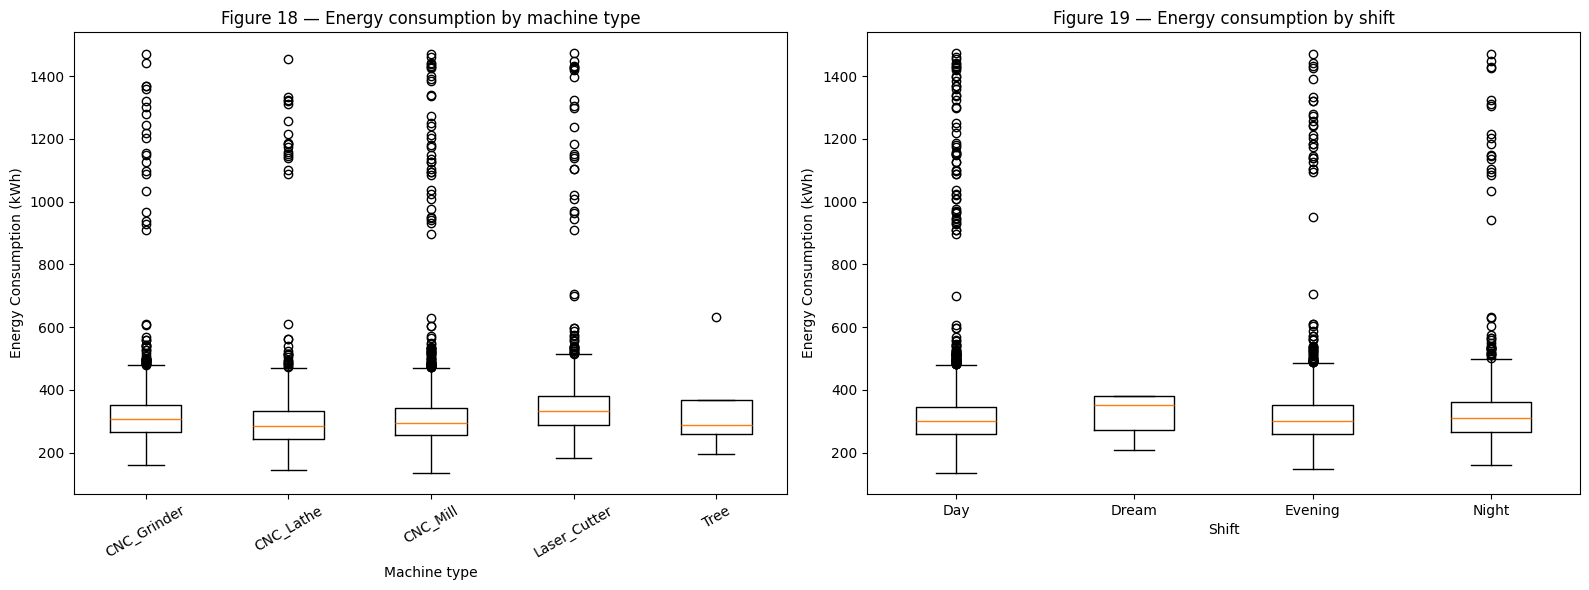

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

machine_groups = [
    g[TARGET].dropna().to_numpy()
    for _, g in df.groupby("Machine_Type")
]
machine_labels = list(df.groupby("Machine_Type").groups.keys())
axes[0].boxplot(machine_groups, labels=machine_labels)
axes[0].set_title("Figure 18 — Energy consumption by machine type")
axes[0].set_xlabel("Machine type")
axes[0].set_ylabel("Energy Consumption (kWh)")
axes[0].tick_params(axis="x", rotation=30)

shift_groups = [
    g[TARGET].dropna().to_numpy()
    for _, g in df.groupby("Shift")
]
shift_labels = list(df.groupby("Shift").groups.keys())
axes[1].boxplot(shift_groups, labels=shift_labels)
axes[1].set_title("Figure 19 — Energy consumption by shift")
axes[1].set_xlabel("Shift")
axes[1].set_ylabel("Energy Consumption (kWh)")

plt.tight_layout()
save_and_show("Figure_18_19_Energy_by_Machine_Type_and_Shift.png")


# 11. Temporal exploration

`Production_Date` is a date feature and the project brief states that it can be transformed into calendar or seasonal features. For Part 1, we inspect the time dimension without claiming that a temporal pattern is causal.


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots/Figure_20_Monthly_Mean_Energy_Consumption.png


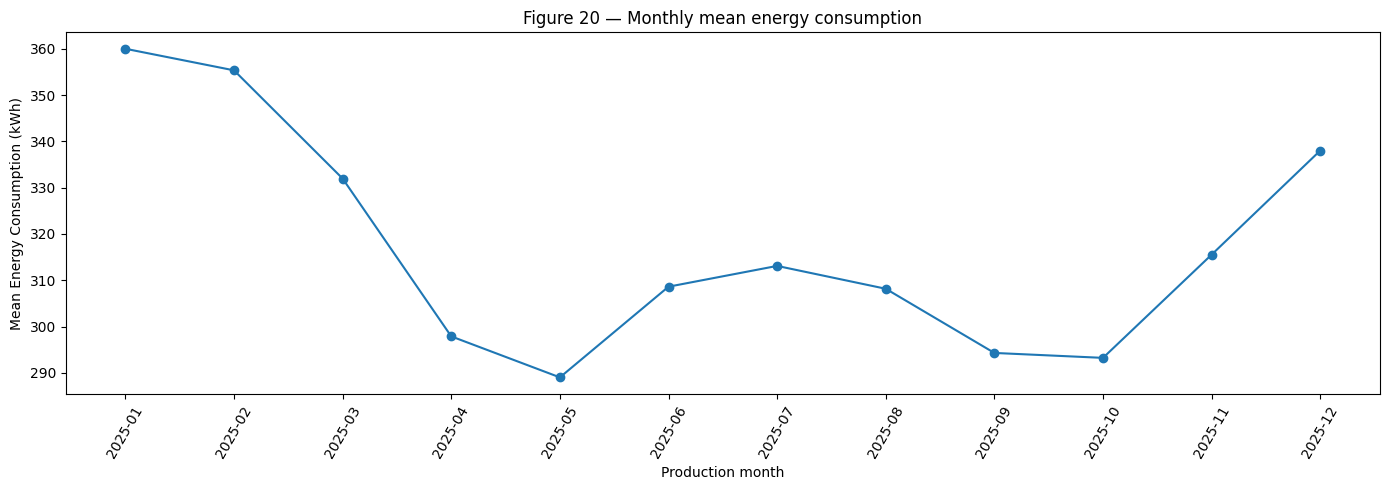

,Production_Month,count,mean,median
0,2025-01,839,360.020,343.680
1,2025-02,763,355.350,333.030
2,2025-03,865,331.970,310.140
3,2025-04,845,297.870,282.450
4,2025-05,786,289.010,274.280
5,2025-06,805,308.610,291.020
6,2025-07,859,313.100,303.720
7,2025-08,850,308.160,294.680
8,2025-09,792,294.290,279.840
9,2025-10,815,293.230,279.150


In [58]:
# Monthly energy overview.
df["Production_Month"] = df[DATE_COL].dt.to_period("M").astype(str)

monthly = (
    df.groupby("Production_Month")[TARGET]
    .agg(["count", "mean", "median"])
    .reset_index()
)

plt.figure(figsize=(14, 5))
plt.plot(monthly["Production_Month"], monthly["mean"], marker="o")
plt.xticks(rotation=60)
plt.xlabel("Production month")
plt.ylabel("Mean Energy Consumption (kWh)")
plt.title("Figure 20 — Monthly mean energy consumption")
plt.tight_layout()
save_and_show("Figure_20_Monthly_Mean_Energy_Consumption.png")

display(monthly.round(2))


# 12. Consolidated evidence table for brainstorming

The table below provides quantitative evidence that can be cited directly in the brainstorming section. It combines target correlations, group means, missingness, and IQR outlier counts.


In [59]:
# Strongest absolute correlations.
strong_corr = target_corr.abs().sort_values(ascending=False).head(8).to_frame("abs_Pearson_r")
strong_corr["Pearson_r"] = target_corr.loc[strong_corr.index]
strong_corr = strong_corr[["Pearson_r", "abs_Pearson_r"]]

print("Strongest target correlations:")
display(strong_corr.round(3))

print("\nMachine type target means:")
display(
    df.groupby("Machine_Type")[TARGET]
      .agg(["count", "mean", "median"])
      .sort_values("mean", ascending=False)
      .round(2)
)

print("\nShift target means:")
display(
    df.groupby("Shift")[TARGET]
      .agg(["count", "mean", "median"])
      .sort_values("mean", ascending=False)
      .round(2)
)

print("\nHighest missingness:")
display(missing_table[missing_table["missing_count"] > 0].head(10))

print("\nLargest IQR outlier counts:")
display(outlier_table.head(10).round(2))


Strongest target correlations:


,Pearson_r,abs_Pearson_r
Product_Complexity_Index,0.342,0.342
Spindle_Load_pct,0.330,0.330
Tool_Wear_Index,0.293,0.293
Material_Hardness_HB,0.254,0.254
Operating_Hours_per_Day,0.220,0.220
Days_Since_Maintenance,0.199,0.199
Vibration_mm_s,0.189,0.189
Ambient_Temperature_C,-0.155,0.155



Machine type target means:


,count,mean,median
Machine_Type,,,
Laser_Cutter,1911,348.170,331.420
Tree,5,347.720,286.880
CNC_Grinder,2191,320.070,306.630
CNC_Mill,3564,310.200,293.960
CNC_Lathe,2168,297.770,284.940



Shift target means:


,count,mean,median
Shift,,,
Night,2037,324.090,311.330
Dream,5,318.790,351.620
Evening,2815,317.420,301.730
Day,4982,313.970,299.230



Highest missingness:


,missing_count,missing_pct
Tool_Wear_Index,617,6.020
Vibration_mm_s,512,5.000
Energy_Consumption_kWh,411,4.010
Average_Machine_Temperature_C,411,4.010
Humidity_pct,310,3.020



Largest IQR outlier counts:


,feature,Q1,Q3,IQR,lower_fence,upper_fence,outlier_count,outlier_pct
0,Operator_Experience_years,3.060,8.340,5.280,-4.860,16.260,329,3.210
1,Days_Since_Maintenance,18.000,44.500,26.500,-21.750,84.250,307,3.000
2,Production_Volume_units,404.000,629.000,225.000,66.500,966.500,257,2.510
3,Energy_Consumption_kWh,260.700,350.510,89.820,125.970,485.230,223,2.270
4,Average_Machine_Temperature_C,70.460,77.690,7.240,59.610,88.550,166,1.690
5,Tool_Wear_Index,0.310,0.530,0.220,-0.010,0.860,148,1.540
6,Cycle_Time_sec,75.270,100.790,25.520,37.000,139.070,125,1.220
7,Vibration_mm_s,2.000,2.820,0.830,0.750,4.060,113,1.160
8,Material_Hardness_HB,230.100,275.800,45.700,161.550,344.350,59,0.580
9,Operating_Hours_per_Day,13.530,18.470,4.940,6.120,25.870,42,0.410


# 13. Brainstorming: findings, hypotheses, and questions

This section is deliberately separated into **observed findings**, **testable hypotheses**, and **open questions**. That distinction prevents an EDA association from being presented as a causal conclusion.

## 13.1 Finding 1 — Higher spindle load is associated with higher energy consumption

**Evidence:** Figure 12 shows a positive Pearson association between `Spindle_Load_pct` and the target, while Figure 16 shows the target mean increasing substantially across higher spindle-load bands. Figure 17 provides a LOWESS view of the relationship.

**Interpretation:** Higher machine/process load is associated with higher energy consumption in the supplied observations. The pattern is consistent with the project scenario's description of a potential overload penalty.

**Hypothesis H1:** Energy consumption increases nonlinearly as spindle load approaches the upper operating range.

**Question:** Is there a threshold above which the marginal energy cost of additional spindle load increases sharply?

---

## 13.2 Finding 2 — Machine temperature is related to energy consumption, but the extreme tail needs investigation

**Evidence:** Figure 12 provides the linear correlation, while Figures 8–10 and Figure 17 show the distribution and nonlinear trend. The dataset contains a small number of very high temperature values beyond the main operating range.

**Interpretation:** Energy is higher across much of the higher-temperature operating range, but extreme temperature observations may represent unusual operating conditions, measurement problems, or intentionally generated nonlinear cases.

**Hypothesis H2:** Energy consumption increases more rapidly after a machine-temperature threshold.

**Question:** Do the extreme temperature observations correspond to systematically different machine types, operating loads, or maintenance conditions?

---

## 13.3 Finding 3 — Longer time since maintenance is associated with higher energy consumption

**Evidence:** Figure 12 shows a positive association between `Days_Since_Maintenance` and energy, while Figure 16 shows increasing mean energy in the higher maintenance-delay bands.

**Interpretation:** The observed association is consistent with the project scenario's equipment-condition and maintenance framing.

**Hypothesis H3:** The energy penalty associated with additional days since maintenance is nonlinear and becomes stronger after a maintenance-delay threshold.

**Question:** Does maintenance delay interact with `Tool_Wear_Index`, `Vibration_mm_s`, or `Machine_Age_years`?

---

## 13.4 Finding 4 — Product complexity and spindle load are candidate production/process drivers

**Evidence:** Figure 12 identifies `Product_Complexity_Index` and `Spindle_Load_pct` among the more strongly associated numerical variables with the target. Figure 14 also jointly visualizes operating hours, production volume, product complexity, and energy.

**Interpretation:** More complex production requirements may be associated with higher energy use, but production volume alone has a comparatively weak linear association in the raw data.

**Hypothesis H4:** Product complexity has a stronger effect on energy when combined with high spindle load or long operating hours.

**Question:** Are interactions between complexity and machine condition more informative than either variable alone?

---

## 13.5 Finding 5 — The target contains substantial high-end observations

**Evidence:** Figure 9 shows the target's box-plot structure, Figure 11 identifies IQR-based target outliers, and the target-focused table lists the highest observations.

**Interpretation:** High energy-consumption observations are statistically unusual under the IQR rule, but they may be exactly the operational cases management wants to diagnose. They should therefore be investigated rather than automatically removed.

**Hypothesis H5:** High-energy observations are associated with combinations of operating conditions rather than one single predictor.

**Question:** Can the high-energy cases be separated into interpretable operating regimes using combinations of load, temperature, maintenance delay, complexity, and operating hours?

---

## 13.6 Finding 6 — Data-quality issues must be resolved before final modeling

**Evidence:** The integrity checks show 10,250 rows, non-unique `Observation_ID` values, missing target values, and unexpected category values (`Tree` and `Dream`). Figure 2 documents missingness.

**Interpretation:** These are not merely cosmetic issues. They can affect model training, group comparisons, and feature engineering.

**Hypothesis H6:** Some apparent extreme patterns may be influenced by data-quality anomalies rather than production behavior.

**Question:** Are duplicate identifiers intentional repeated machine-day observations, accidental duplicates, or rows with altered measurements? Are `Tree` and `Dream` data-entry errors or intentionally injected anomalies?

**Part 1 decision:** Do not silently modify these records. Document and validate them before modeling.


# 14. Brainstorming matrix — evidence to next analysis

| Evidence / finding | Figure(s) / table(s) | Hypothesis | Next analysis |
|---|---|---|---|
| Higher spindle load corresponds to higher energy | Figures 12, 16, 17 | H1: upper-load nonlinear penalty | Piecewise regression / spline / tree-based comparison |
| Higher temperature is associated with higher energy in the main range | Figures 8–10, 12, 17 | H2: overheating threshold | Threshold analysis; inspect extreme-temperature rows |
| Energy rises with maintenance delay | Figures 12, 16, 17 | H3: nonlinear maintenance penalty | Interaction with tool wear and vibration |
| Complexity and process load are associated with energy | Figures 12, 14 | H4: interaction effect | 2D interaction plots / feature interaction analysis |
| Target has high-end IQR outliers | Figures 9, 11 | H5: high energy arises from combinations | Profile high-energy cases and compare feature distributions |
| Missingness and category/ID anomalies exist | Figure 2 and integrity checks | H6: data-quality anomalies can distort analysis | Validate source generation rules before modeling |

This matrix provides explicit cross-references from each brainstorming statement to the notebook evidence, satisfying the project's requirement that statements be supported by images or text parts.


# 15. Project Part 1 conclusion

### What the EDA establishes

1. The supplied CSV is a **20-column manufacturing machine-day dataset** with 10,250 rows.
2. `Energy_Consumption_kWh` is the regression target specified by the project.
3. Missing values occur in several process/environment variables and in the target itself.
4. The data contains categorical anomalies and duplicate identifier values that require source-level clarification.
5. Multiple process variables show meaningful associations with energy consumption, particularly spindle load, product complexity, tool wear, material hardness, operating hours, and maintenance delay.
6. The relationship structure is not adequately described by linear correlation alone; binned means and LOWESS plots reveal patterns worth testing in later modeling.
7. Potential outliers are present and should be investigated in context rather than automatically deleted.
8. The main hypotheses concern **overload thresholds, overheating thresholds, maintenance-delay effects, and interactions between production requirements and machine condition**.

### Modeling preparation

For the later regression stage, the analysis suggests that the workflow should explicitly address:

- missing predictor and target values;
- anomalous categorical levels;
- duplicate `Observation_ID` values;
- appropriate treatment of `Production_Date`;
- nonlinear relationships;
- interactions;
- and the distinction between genuine operational extremes and data-quality errors.

No final modeling decision is made in this Part 1 notebook.


# 16. External references

The following sources support the EDA methodology used in this notebook. They are methodological references, not sources of facts about the supplied manufacturing dataset.

1. **Heckert, N. A., & Filliben, J. (2003).** *NIST/SEMATECH e-Handbook of Statistical Methods — Chapter 1: Exploratory Data Analysis.* National Institute of Standards and Technology (NIST).  
   https://www.nist.gov/publications/nistsematech-e-handbook-statistical-methods-chapter-1-exploratory-data-analysis

2. **NIST/SEMATECH Engineering Statistics Handbook.** *What are outliers in the data?*  
   https://www.itl.nist.gov/div898/handbook/prc/section1/prc16.htm

3. **pandas documentation.** `pandas.read_csv` and missing-value parsing behavior.  
   https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html

4. **scikit-learn documentation.** *Imputation of missing values.*  
   https://scikit-learn.org/stable/modules/impute.html

### Methodological note

NIST describes EDA as a graphical/statistical approach intended to uncover structure, detect unusual observations, and inform later modeling. The notebook follows that philosophy by combining distributions, outlier screening, correlations, relationship plots, grouped comparisons, and hypothesis generation rather than relying on one statistic alone.


# Appendix A — Reusable diagnostic code

The following compact cells can be reused during later revisions of the project without changing the raw dataset.


In [60]:
# Raw-data snapshot for reproducibility
print("Raw dataset shape:", df_raw.shape)
print("Raw columns:")
for i, c in enumerate(df_raw.columns, start=1):
    print(f"{i:02d}. {c}")

print("\nRaw missing-value counts:")
display(df_raw.isna().sum().to_frame("missing_count"))

print("\nRaw categorical levels:")
for c in ["Machine_Type", "Shift"]:
    print(c, sorted(df_raw[c].dropna().unique().tolist()))


Raw dataset shape: (10250, 20)
Raw columns:
01. Observation_ID
02. Production_Date
03. Machine_ID
04. Machine_Type
05. Shift
06. Machine_Age_years
07. Operating_Hours_per_Day
08. Production_Volume_units
09. Product_Complexity_Index
10. Material_Hardness_HB
11. Cycle_Time_sec
12. Spindle_Load_pct
13. Average_Machine_Temperature_C
14. Vibration_mm_s
15. Tool_Wear_Index
16. Days_Since_Maintenance
17. Operator_Experience_years
18. Ambient_Temperature_C
19. Humidity_pct
20. Energy_Consumption_kWh

Raw missing-value counts:


,missing_count
Observation_ID,0
Production_Date,0
Machine_ID,0
Machine_Type,0
Shift,0
Machine_Age_years,0
Operating_Hours_per_Day,0
Production_Volume_units,0
Product_Complexity_Index,0
Material_Hardness_HB,0



Raw categorical levels:
Machine_Type ['CNC_Grinder', 'CNC_Lathe', 'CNC_Mill', 'Laser_Cutter', 'Tree']
Shift ['Day', 'Dream', 'Evening', 'Night']
